# Validación, simulación y remuestreo de los resultados de la Sumativa 1

**Evaluación Sumativa 2 · MCDI501 Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial · Universidad Andrés Bello

| | |
|---|---|
| **Grupo** | 6 |
| **Integrantes** | Marco Álvarez Araya · Ricardo Jaramillo |
| **Docente** | Dr. Jean Paul Maidana González |
| **Fecha** | 20-10-2026 |
| **Dataset** | E-Commerce Shipping Data (Prachi13, Kaggle): 10.999 envíos, 12 variables |

## Propósito

La Sumativa 1 (S1) estimó parámetros con intervalos de confianza clásicos, contrastó hipótesis con pruebas paramétricas y detectó que el bloque inicial del archivo (ID ≤ 3.135) tiene un 100 % de envíos fuera de plazo y concentra los descuentos mayores a 10. Esta entrega **no recalcula S1 desde cero: lo pone a prueba**. Cada parámetro, prueba y correlación de S1 se somete a métodos computacionales que no dependen de los supuestos paramétricos:

| Sección | Pregunta | Método | Insumo de S1 |
|---|---|---|---|
| 1 | ¿Los intervalos de S1 se sostienen sin el supuesto normal? | Bootstrap percentil y BCa (10.000 remuestras) | Tabla 10 y Tabla 11 |
| 2 | ¿Las pruebas de S1 llegan a la misma decisión sin supuestos distribucionales? | Permutación (10.000 y 100.000 permutaciones) | Tablas 12, 14 y 15 |
| 3 | ¿Qué correlaciones son estables? | IC bootstrap de ρ de Spearman | Tabla 5 |
| 4 | ¿Qué implican los parámetros de S1 para un lote de envíos? | Monte Carlo con incertidumbre de parámetros y datos sintéticos | Tablas 4, 6 y 15 |
| 5 | ¿Qué conclusiones dependen de outliers, del orden del archivo o del corte elegido? | Jackknife, estimadores robustos, bootstrap por bloques, barrido del corte | Tablas 8 y 16 |
| 6 | ¿Qué llega validado a la Sumativa 3? | Reporte de resultados validados | Todas |

**Eje transversal.** Cada análisis se repite en el conjunto completo y en el subconjunto ID > 3.135, siguiendo la línea validada por el docente en la retroalimentación de S1. Por indicación del docente se agregan los intervalos bootstrap de las **medianas** de peso y descuento y la comparación de medianas del peso por grupo.

**Reproducibilidad.** Semilla 42, generador `numpy.random.default_rng` reiniciado al inicio de cada sección, número de réplicas declarado como constante y verificado con `assert`. El notebook lee los parámetros de S1 desde `S1/resultados/tablas/` y comprueba que coincidan con el recálculo antes de usarlos. Todas las tablas y figuras citadas en el informe se exportan a `S2/resultados/`.

## 0. Entorno, datos e insumos de S1

### 0.1 Librerías, semilla y constantes

Las constantes `B_*` fijan el número de réplicas de cada método. La rúbrica exige al menos 10.000 remuestras, permutaciones e iteraciones; los `assert` impiden ejecutar el notebook con menos. Las remuestras se generan **por lotes** (`LOTE` filas por vez) para mantener acotada la memoria: con n = 10.999, una matriz completa de 10.000 × 10.999 índices ocuparía cerca de 900 MB.

In [1]:
import hashlib
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

SEED = 42                # semilla única, documentada (misma que S1)
CONFIANZA = 0.95
ALFA = 1 - CONFIANZA
Z = stats.norm.ppf(1 - ALFA / 2)

B_BOOT = 10_000          # remuestras bootstrap (secciones 1, 3 y 5)
B_PERM = 10_000          # permutaciones (sección 2)
B_PERM_FINO = 100_000    # permutaciones adicionales para valores p cercanos a 0,05
B_MC = 10_000            # iteraciones Monte Carlo (sección 4)
LOTE = 250               # filas de remuestreo procesadas por vez
CORTE_ID = 3135          # corte del bloque inicial definido en S1 (sección 2.6)

assert min(B_BOOT, B_PERM, B_MC) >= 10_000, "La rúbrica exige al menos 10.000 réplicas"

# Paleta: un color por conjunto y uno por método de intervalo.
C_COMPLETO, C_SUB = "#2A74B0", "#C7781F"
C_CLASICO, C_PERC, C_BCA = "#7F7F7F", "#2A74B0", "#BC5A45"
COLOR_CONJ = {"Completo": C_COMPLETO, "ID > 3.135": C_SUB}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 8, "axes.titlesize": 8.5,
    "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.5,
    "lines.linewidth": 1.2, "axes.linewidth": 0.7, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#9A9A9A",
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.7,
    "axes.axisbelow": True, "legend.frameon": False,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

# Rutas: el notebook vive en S2/notebooks/; la raíz del repositorio contiene S1/, S2/ y datos/.
RAIZ = Path.cwd()
while not ((RAIZ / "S1").is_dir() and (RAIZ / "datos").is_dir()):
    if RAIZ.parent == RAIZ:
        raise FileNotFoundError("No se encontró la raíz del repositorio (carpetas S1/ y datos/)")
    RAIZ = RAIZ.parent
S1_TABLAS = RAIZ / "S1" / "resultados" / "tablas"
DIR_TABLAS = RAIZ / "S2" / "resultados" / "tablas"
DIR_FIGURAS = RAIZ / "S2" / "resultados" / "figuras"
DIR_TABLAS.mkdir(parents=True, exist_ok=True)
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)


def guardar_tabla(tabla, nombre, index=False):
    # Exporta la tabla a S2/resultados/tablas/<nombre>.csv y la devuelve para mostrarla.
    tabla.to_csv(DIR_TABLAS / f"{nombre}.csv", index=index, encoding="utf-8")
    return tabla


def es(x, d=2):
    # Número con la convención del informe: 3.634,02 y signo menos tipográfico.
    t = f"{x:,.{d}f}"
    return t.replace(",", "§").replace(".", ",").replace("§", ".").replace("-", "−")


def _marca_es(v, pos=None):
    t = f"{v:,.10g}"
    return t.replace(",", "§").replace(".", ",").replace("§", ".").replace("-", "−")


def guardar_figura(fig, nombre):
    # Exporta la figura a S2/resultados/figuras/<nombre>.png con decimales en coma.
    for ax in fig.axes:
        for eje in (ax.xaxis, ax.yaxis):
            if eje.get_scale() == "linear" and type(eje.get_major_formatter()) is matplotlib.ticker.ScalarFormatter:
                eje.set_major_formatter(matplotlib.ticker.FuncFormatter(_marca_es))
    fig.savefig(DIR_FIGURAS / f"{nombre}.png", bbox_inches="tight", facecolor="white")


def s1(nombre, **kw):
    # Lee una tabla exportada por el notebook de S1.
    return pd.read_csv(S1_TABLAS / f"{nombre}.csv", **kw)


def s1_valores(nombre):
    # Tablas de S1 con formato clave-valor (pruebas de hipótesis).
    t = s1(nombre)
    return pd.Series(t.iloc[:, 1].values, index=t.iloc[:, 0].values)


print(f"Python {platform.python_version()} · numpy {np.__version__} · pandas {pd.__version__} · "
      f"scipy {scipy.__version__} · matplotlib {matplotlib.__version__}")
print(f"Semilla = {SEED} · B_BOOT = {B_BOOT:,} · B_PERM = {B_PERM:,} (+{B_PERM_FINO:,}) · B_MC = {B_MC:,}")

Python 3.13.16 · numpy 2.5.3 · pandas 3.0.5 · scipy 1.18.1 · matplotlib 3.11.2
Semilla = 42 · B_BOOT = 10,000 · B_PERM = 10,000 (+100,000) · B_MC = 10,000


### 0.2 Carga del CSV original y control de versión

Se verifica la huella SHA-256 del archivo para garantizar que se analiza exactamente la misma versión que en S1. El subconjunto de sensibilidad se define con el mismo corte de S1 y se comprueba la propiedad que lo motivó: en ID ≤ 3.135 todos los envíos llegaron fuera de plazo.

In [2]:
RUTA_CSV = RAIZ / "datos" / "originales" / "ecommerce-shipping.csv"
SHA_ESPERADO = "dcdc3fd8f0507ec400174ef70d88d634321cc2ce8f4ea11bf4e8c847fdd325b3"
sha = hashlib.sha256(RUTA_CSV.read_bytes()).hexdigest()
assert sha == SHA_ESPERADO, "El CSV no coincide con la versión analizada en S1"

df = pd.read_csv(RUTA_CSV)
Y = "Reached.on.Time_Y.N"   # 1 = fuera de plazo, 0 = a tiempo (interpretación de S1)
assert (df["ID"].to_numpy() == np.arange(1, len(df) + 1)).all(), "El archivo debe estar ordenado por ID"
assert df.loc[df["ID"] <= CORTE_ID, Y].eq(1).all(), "Propiedad del bloque inicial no verificada"

CONJUNTOS = {"Completo": df, "ID > 3.135": df[df["ID"] > CORTE_ID].reset_index(drop=True)}
for nombre, d in CONJUNTOS.items():
    print(f"{nombre:<11} n = {len(d):>6,}   fuera de plazo = {d[Y].mean():.4%}")
print("SHA-256 verificado:", sha[:16], "…")

Completo    n = 10,999   fuera de plazo = 59.6691%
ID > 3.135  n =  7,864   fuera de plazo = 43.5910%
SHA-256 verificado: dcdc3fd8f0507ec4 …


### 0.3 Parámetros de S1 que se validan

Antes de usar un parámetro de S1 se recalcula desde el CSV y se compara con el valor exportado por el notebook de S1. Si alguno no coincide, el notebook se detiene: así se garantiza que S2 trabaja sobre **los resultados propios de S1** y no sobre cifras transcritas a mano.

In [3]:
t10, t11, t15 = s1("tab10_intervalos_confianza"), s1("tab11_sensibilidad_ic"), s1("tab15_pruebas_complementarias")
w1, w1s = s1_valores("tab12_prueba1_welch_peso"), s1_valores("tab12b_prueba1_welch_peso_sensibilidad")
c2, c2s = s1_valores("tab14_prueba2_chi2_importancia"), s1_valores("tab14b_prueba2_chi2_sensibilidad")
t05 = s1("tab05_correlacion_objetivo", index_col=0)
t07 = s1("tab07_numericas_por_grupo")

comp, sub = CONJUNTOS["Completo"], CONJUNTOS["ID > 3.135"]


def welch(d, var="Weight_in_gms"):
    return stats.ttest_ind(d.loc[d[Y] == 1, var], d.loc[d[Y] == 0, var], equal_var=False)


def chi2_importancia(d):
    return stats.chi2_contingency(pd.crosstab(d["Product_importance"], d[Y]), correction=False)


controles = [
    ("Proporción fuera de plazo", t10.loc[0, "estimacion"], comp[Y].mean()),
    ("Costo medio", t10.loc[2, "estimacion"], comp["Cost_of_the_Product"].mean()),
    ("Peso medio", t10.loc[3, "estimacion"], comp["Weight_in_gms"].mean()),
    ("Descuento medio", t10.loc[4, "estimacion"], comp["Discount_offered"].mean()),
    ("Peso medio (ID > 3.135)", t11.loc[1, "sensibilidad_estimacion"], sub["Weight_in_gms"].mean()),
    ("t de Welch, peso", float(w1["t"]), welch(comp).statistic),
    ("t de Welch, peso (ID > 3.135)", float(w1s["t"]), welch(sub).statistic),
    ("χ² importancia", float(c2["chi2"]), chi2_importancia(comp)[0]),
    ("χ² importancia (ID > 3.135)", float(c2s["chi2"]), chi2_importancia(sub)[0]),
    ("ρ Spearman descuento", t05.loc["Discount_offered", "spearman"],
     stats.spearmanr(comp["Discount_offered"], comp[Y])[0]),
    ("Mediana peso, fuera de plazo", float(t07.query("variable == 'Weight_in_gms' and estadistico == 'median'")["Fuera de plazo"].iloc[0]),
     comp.loc[comp[Y] == 1, "Weight_in_gms"].median()),
]
tab_control = pd.DataFrame(controles, columns=["parametro", "valor_S1", "recalculo_S2"])
tab_control["coincide"] = np.isclose(tab_control["valor_S1"], tab_control["recalculo_S2"], rtol=1e-10, atol=0)
assert tab_control["coincide"].all(), "Algún parámetro de S1 no coincide con el recálculo"
guardar_tabla(tab_control, "s2_tab00_control_insumos_s1")
tab_control

,parametro,valor_S1,recalculo_S2,coincide
0,Proporción fuera de plazo,0.596691,0.596691,True
1,Costo medio,210.196836,210.196836,True
2,Peso medio,3634.016729,3634.016729,True
3,Descuento medio,13.373216,13.373216,True
4,Peso medio (ID > 3.135),4139.627035,4139.627035,True
5,"t de Welch, peso",-29.272229,-29.272229,True
6,"t de Welch, peso (ID > 3.135)",-1.848940,-1.848940,True
7,χ² importancia,12.211164,12.211164,True
8,χ² importancia (ID > 3.135),5.643693,5.643693,True
9,ρ Spearman descuento,0.335108,0.335108,True


## 1. Validación de los intervalos de S1 mediante bootstrap

### 1.1 Qué se valida y con qué métodos

S1 construyó intervalos al 95 % con la aproximación normal: Wald para la proporción y TCL para las medias. Ambos suponen que la distribución muestral del estimador es aproximadamente normal y simétrica. El bootstrap no paramétrico reemplaza ese supuesto por la distribución empírica: se remuestrea el conjunto **con reposición** B = 10.000 veces, se recalcula el estimador en cada remuestra $\hat\theta^*_b$ y se usa la distribución de esas réplicas (Efron y Tibshirani, 1993).

- **Percentil:** $[\hat\theta^*_{(\alpha/2)},\ \hat\theta^*_{(1-\alpha/2)}]$. No supone simetría, pero no corrige el sesgo.
- **BCa** (Efron, 1987): ajusta los percentiles con la corrección de sesgo $z_0 = \Phi^{-1}\big(\#\{\hat\theta^*_b < \hat\theta\}/B\big)$ y la aceleración $a = \sum(\bar\theta_{(\cdot)}-\hat\theta_{(i)})^3 / \big[6\{\sum(\bar\theta_{(\cdot)}-\hat\theta_{(i)})^2\}^{3/2}\big]$, donde $\hat\theta_{(i)}$ es el estimador jackknife sin la observación $i$. Los percentiles corregidos son $\alpha_{1,2} = \Phi\big(z_0 + \frac{z_0+z_{\alpha/2,\,1-\alpha/2}}{1-a(z_0+z_{\alpha/2,\,1-\alpha/2})}\big)$. Con datos discretos hay empates con $\hat\theta$; siguiendo la convención de `scipy.stats.bootstrap`, los empates cuentan como media unidad. Para las medianas el jackknife es constante cuando hay empates en el centro de la distribución (el jackknife no es consistente para la mediana; Efron y Tibshirani, 1993), por lo que la aceleración es 0/0: en ese caso se informa la variante **BC** ($a = 0$), que conserva la corrección de sesgo.

**Parámetros validados (12 intervalos):** los cuatro estimados en S1 (proporción fuera de plazo y medias de costo, peso y descuento) y, por indicación del docente, las **medianas** de peso y descuento, en los dos conjuntos. Para las medianas, S1 no tenía intervalo clásico; como referencia clásica se usa el **intervalo exacto por estadísticos de orden**, que no supone ninguna distribución: si $j$ es el mayor entero con $P(\text{Bin}(n, 0{,}5) < j) \le \alpha/2$, el intervalo es $[x_{(j)},\ x_{(n-j+1)}]$.

### 1.2 Funciones

Las remuestras se generan por lotes con `rng.integers`. El jackknife de la media y de la mediana se calcula en forma cerrada (sin recalcular n veces), y la fórmula cerrada de la mediana se verifica contra el cálculo directo antes de usarla.

In [4]:
def remuestrear(x, estadisticos, B, rng, lote=LOTE, suavizado=0.0):
    # Bootstrap no paramétrico por lotes. `estadisticos`: {nombre: función(matriz) -> vector por fila}.
    # Si suavizado > 0, suma ruido uniforme en (-suavizado, suavizado) a cada valor remuestreado.
    n = len(x)
    salida = {k: np.empty(B) for k in estadisticos}
    for ini in range(0, B, lote):
        m = min(lote, B - ini)
        X = x[rng.integers(0, n, size=(m, n))]
        if suavizado:
            X = X + rng.uniform(-suavizado, suavizado, size=X.shape)
        for k, f in estadisticos.items():
            salida[k][ini:ini + m] = f(X)
    return salida


def jackknife_media(x):
    return (x.sum() - x) / (len(x) - 1)


def jackknife_mediana(x):
    # Mediana sin la observación i, en forma cerrada (por posición en el arreglo ordenado).
    xs = np.sort(x).astype(float)
    n = len(xs)
    j = np.arange(n)
    if n % 2:                       # n impar: mediana en m; al quitar uno quedan n-1 (par)
        m = n // 2
        return np.where(j < m, (xs[m] + xs[m + 1]) / 2,
               np.where(j > m, (xs[m - 1] + xs[m]) / 2, (xs[m - 1] + xs[m + 1]) / 2))
    m = n // 2                      # n par: al quitar uno quedan n-1 (impar)
    return np.where(j <= m - 1, xs[m], xs[m - 1])


_r = np.random.default_rng(0)
for n_prueba in (11, 12, 37, 40):   # verificación contra el cálculo directo (ambas paridades, con empates)
    x_p = _r.integers(0, 6, n_prueba).astype(float)
    directo = np.sort([np.median(np.delete(x_p, i)) for i in range(n_prueba)])
    assert np.allclose(np.sort(jackknife_mediana(x_p)), directo)


def bca(reps, theta, jack, alfa=ALFA):
    # IC BCa. Devuelve (inf, sup, z0, a, estado). Estado: "definido", "BC (a = 0)" si el jackknife
    # es constante, o "no definido" si la distribución bootstrap es degenerada (un solo valor).
    prop = (np.sum(reps < theta) + 0.5 * np.sum(reps == theta)) / len(reps)
    dif = jack.mean() - jack
    den = 6.0 * np.sum(dif ** 2) ** 1.5
    if np.ptp(reps) == 0 or prop in (0.0, 1.0):
        return np.nan, np.nan, np.nan, np.nan, "no definido"
    z0 = stats.norm.ppf(prop)
    if den == 0:
        # Jackknife constante (mediana con empates): la aceleración es 0/0. Se usa la variante
        # BC (a = 0), que conserva la corrección de sesgo (Efron y Tibshirani, 1993).
        a, estado = 0.0, "BC (a = 0)"
    else:
        a, estado = np.sum(dif ** 3) / den, "definido"
    zl, zu = stats.norm.ppf([alfa / 2, 1 - alfa / 2])
    a1 = stats.norm.cdf(z0 + (z0 + zl) / (1 - a * (z0 + zl)))
    a2 = stats.norm.cdf(z0 + (z0 + zu) / (1 - a * (z0 + zu)))
    lo, hi = np.percentile(reps, [100 * a1, 100 * a2])
    return lo, hi, z0, a, estado


def ic_mediana_orden(x, alfa=ALFA):
    # IC exacto de la mediana por estadísticos de orden (sin supuestos distribucionales).
    xs = np.sort(x)
    n = len(xs)
    j = int(stats.binom.ppf(alfa / 2, n, 0.5))
    if stats.binom.cdf(j - 1, n, 0.5) > alfa / 2:
        j -= 1
    cobertura = 1 - 2 * stats.binom.cdf(j - 1, n, 0.5)
    return xs[j - 1], xs[n - j], cobertura


media_filas = lambda X: X.mean(axis=1)
mediana_filas = lambda X: np.median(X, axis=1)
print("Funciones listas; jackknife de la mediana verificado contra el cálculo directo.")

Funciones listas; jackknife de la mediana verificado contra el cálculo directo.


### 1.3 Remuestreo de los 12 parámetros

Para cada conjunto y variable se generan 10.000 remuestras y en cada una se calculan la media y la mediana (mismas remuestras para ambos estimadores). El intervalo clásico se toma **tal como lo exportó S1** (Tabla 10 para el conjunto completo y Tabla 11 para el subconjunto). La única excepción es la proporción en el subconjunto: S1 la informó como porcentaje (Tabla 8) sin intervalo, y aquí se calcula su intervalo de Wald con la misma fórmula de S1.

In [5]:
rng = np.random.default_rng(SEED)      # sección 1: generador reiniciado

VARIABLES = {
    "Proporción fuera de plazo": (Y, ["media"]),
    "Costo medio": ("Cost_of_the_Product", ["media"]),
    "Peso": ("Weight_in_gms", ["media", "mediana"]),
    "Descuento": ("Discount_offered", ["media", "mediana"]),
}
# Intervalos clásicos exportados por S1 (fila de la Tabla 10 / Tabla 11).
CLASICO_S1 = {
    ("Completo", "Proporción fuera de plazo"): (t10.loc[0, "ic_inferior"], t10.loc[0, "ic_superior"], t10.loc[0, "error_estandar"], "Wald · S1 Tabla 10"),
    ("Completo", "Costo medio"): (t10.loc[2, "ic_inferior"], t10.loc[2, "ic_superior"], t10.loc[2, "error_estandar"], "Normal · S1 Tabla 10"),
    ("Completo", "Peso medio"): (t10.loc[3, "ic_inferior"], t10.loc[3, "ic_superior"], t10.loc[3, "error_estandar"], "Normal · S1 Tabla 10"),
    ("Completo", "Descuento medio"): (t10.loc[4, "ic_inferior"], t10.loc[4, "ic_superior"], t10.loc[4, "error_estandar"], "Normal · S1 Tabla 10"),
    ("ID > 3.135", "Costo medio"): (t11.loc[0, "sensibilidad_ic_inferior"], t11.loc[0, "sensibilidad_ic_superior"], None, "Normal · S1 Tabla 11"),
    ("ID > 3.135", "Peso medio"): (t11.loc[1, "sensibilidad_ic_inferior"], t11.loc[1, "sensibilidad_ic_superior"], None, "Normal · S1 Tabla 11"),
    ("ID > 3.135", "Descuento medio"): (t11.loc[2, "sensibilidad_ic_inferior"], t11.loc[2, "sensibilidad_ic_superior"], None, "Normal · S1 Tabla 11"),
}

filas, REPS = [], {}
for conj, d in CONJUNTOS.items():
    for etiqueta, (var, ests) in VARIABLES.items():
        x = d[var].to_numpy(dtype=float)
        n = len(x)
        fs = {"media": media_filas, "mediana": mediana_filas}
        reps = remuestrear(x, {e: fs[e] for e in ests}, B_BOOT, rng)
        for e in ests:
            if etiqueta in ("Proporción fuera de plazo", "Costo medio"):
                nombre = etiqueta
            else:
                nombre = f"{etiqueta} medio" if e == "media" else f"Mediana del {etiqueta.lower()}"
            theta = x.mean() if e == "media" else np.median(x)
            jack = jackknife_media(x) if e == "media" else jackknife_mediana(x)
            r = reps[e]
            REPS[(conj, nombre)] = r
            if e == "mediana":
                ci_lo, ci_hi, cob = ic_mediana_orden(x)
                se_c, metodo = np.nan, f"Orden exacto ({cob:.1%})"
            elif (conj, nombre) in CLASICO_S1:
                ci_lo, ci_hi, se_c, metodo = CLASICO_S1[(conj, nombre)]
                se_c = se_c if se_c is not None else x.std(ddof=1) / np.sqrt(n)
            else:  # proporción en el subconjunto: Wald con la fórmula de S1
                se_c = np.sqrt(theta * (1 - theta) / n)
                ci_lo, ci_hi, metodo = theta - Z * se_c, theta + Z * se_c, "Wald · fórmula S1"
            p_lo, p_hi = np.percentile(r, [100 * ALFA / 2, 100 * (1 - ALFA / 2)])
            b_lo, b_hi, z0, a, estado = bca(r, theta, jack)
            filas.append({
                "conjunto": conj, "parametro": nombre, "n": n, "estimacion": theta,
                "metodo_clasico": metodo, "clasico_inf": ci_lo, "clasico_sup": ci_hi,
                "se_clasico": se_c, "se_bootstrap": r.std(ddof=1),
                "percentil_inf": p_lo, "percentil_sup": p_hi,
                "bca_inf": b_lo, "bca_sup": b_hi, "z0": z0, "a": a, "bca_estado": estado,
                "valores_distintos_bootstrap": len(np.unique(r)), "asimetria_bootstrap": stats.skew(r) if np.ptp(r) else np.nan,
            })

tab_boot = pd.DataFrame(filas)
amp_c = tab_boot["clasico_sup"] - tab_boot["clasico_inf"]
tab_boot["amplitud_percentil_vs_clasico"] = (tab_boot["percentil_sup"] - tab_boot["percentil_inf"]) / amp_c
tab_boot["amplitud_bca_vs_clasico"] = (tab_boot["bca_sup"] - tab_boot["bca_inf"]) / amp_c
tab_boot["desplazamiento_bca_rel_se"] = ((tab_boot["bca_inf"] + tab_boot["bca_sup"]) / 2 - (tab_boot["clasico_inf"] + tab_boot["clasico_sup"]) / 2) / tab_boot["se_bootstrap"]
guardar_tabla(tab_boot, "s2_tab01_bootstrap_ic")
with pd.option_context("display.float_format", "{:,.4f}".format):
    display(tab_boot[["conjunto", "parametro", "estimacion", "metodo_clasico", "clasico_inf", "clasico_sup",
                      "percentil_inf", "percentil_sup", "bca_inf", "bca_sup", "z0", "a", "bca_estado"]])

,conjunto,parametro,estimacion,metodo_clasico,clasico_inf,clasico_sup,percentil_inf,percentil_sup,bca_inf,bca_sup,z0,a,bca_estado
0,Completo,Proporción fuera de plazo,0.5967,Wald · S1 Tabla 10,0.5875,0.6059,0.5874,0.6057,0.5874,0.6056,-0.0033,-0.0006,definido
1,Completo,Costo medio,210.1968,Normal · S1 Tabla 10,209.2986,211.0951,209.2910,211.1010,209.3010,211.1071,0.0104,-0.0002,definido
2,Completo,Peso medio,"3,634.0167",Normal · S1 Tabla 10,"3,603.4542","3,664.5793","3,603.8260","3,663.7386","3,604.1656","3,664.0463",0.0113,-0.0004,definido
3,Completo,Mediana del peso,"4,149.0000",Orden exacto (95.1%),"4,119.0000","4,183.0000","4,119.0000","4,183.0000","4,119.0000","4,184.0000",0.0031,0.0000,BC (a = 0)
4,Completo,Descuento medio,13.3732,Normal · S1 Tabla 10,13.0704,13.6761,13.0717,13.6813,13.0772,13.6869,0.0112,0.0029,definido
5,Completo,Mediana del descuento,7.0000,Orden exacto (95.1%),7.0000,7.0000,7.0000,7.0000,NaN,NaN,NaN,NaN,no definido
6,ID > 3.135,Proporción fuera de plazo,0.4359,Wald · fórmula S1,0.4250,0.4469,0.4252,0.4467,0.4252,0.4467,0.0058,0.0005,definido
7,ID > 3.135,Costo medio,215.8564,Normal · S1 Tabla 11,214.7987,216.9142,214.8244,216.9090,214.8177,216.8972,-0.0095,-0.0005,definido
8,ID > 3.135,Peso medio,"4,139.6270",Normal · S1 Tabla 11,"4,104.6543","4,174.5997","4,104.6005","4,174.9955","4,104.2452","4,174.6162",-0.0040,-0.0017,definido
9,ID > 3.135,Mediana del peso,"4,657.0000",Orden exacto (95.2%),"4,631.0000","4,686.0000","4,631.0000","4,686.0000","4,631.0000","4,686.0000",-0.0187,0.0000,BC (a = 0)


### 1.4 Caso degenerado: la mediana del descuento

El descuento es entero y concentra mucha masa en pocos valores. Si la distribución bootstrap de la mediana queda en un solo valor (o en dos o tres), el intervalo percentil pierde amplitud y la aceleración de BCa resulta 0/0: el jackknife de la mediana es constante. Es una limitación conocida del bootstrap con **estimadores no suaves** y datos discretos. Se documentan dos complementos:

1. La **distribución bootstrap completa** (frecuencia de cada valor), que muestra dónde está realmente la incertidumbre.
2. Un **bootstrap suavizado** (Hall et al., 1989): a cada valor remuestreado se suma ruido uniforme en (−0,5; 0,5), lo que equivale a tratar el descuento como una magnitud continua redondeada al entero. El intervalo resultante interpola entre valores enteros y se informa como complemento, no como reemplazo.

In [6]:
filas_suav = []
for conj, d in CONJUNTOS.items():
    x = d["Discount_offered"].to_numpy(dtype=float)
    r = REPS[(conj, "Mediana del descuento")]
    frec = pd.Series(r).value_counts(normalize=True).sort_index()
    print(f"{conj}: mediana = {np.median(x):g}; distribución bootstrap de la mediana:",
          ", ".join(f"{v:g} → {p:.1%}" for v, p in frec.items()))
    r_s = remuestrear(x, {"mediana": mediana_filas}, B_BOOT, rng, suavizado=0.5)["mediana"]
    lo, hi = np.percentile(r_s, [2.5, 97.5])
    filas_suav.append({"conjunto": conj, "mediana": np.median(x),
                       "valores_bootstrap": "; ".join(f"{v:g}: {p:.4f}" for v, p in frec.items()),
                       "suavizado_inf": lo, "suavizado_sup": hi, "se_suavizado": r_s.std(ddof=1)})
tab_suav = guardar_tabla(pd.DataFrame(filas_suav), "s2_tab01b_mediana_descuento_suavizado")
tab_suav

Completo: mediana = 7; distribución bootstrap de la mediana: 7 → 100.0%
ID > 3.135: mediana = 6; distribución bootstrap de la mediana: 5 → 23.9%, 5.5 → 0.7%, 6 → 75.4%


,conjunto,mediana,valores_bootstrap,suavizado_inf,suavizado_sup,se_suavizado
0,Completo,7.0,7: 1.0000,6.963516,7.207482,0.062375
1,ID > 3.135,6.0,5: 0.2393; 5.5: 0.0065; 6: 0.7542,5.427282,5.650274,0.056854


### 1.5 Verificación cruzada con `scipy.stats.bootstrap`

Para descartar errores de implementación, el BCa propio se compara con el de SciPy (Virtanen et al., 2020) en el costo medio. Cada implementación usa su propio flujo aleatorio, por lo que se esperan diferencias del orden del error de Monte Carlo de los percentiles, no idénticas.

In [7]:
x_c = comp["Cost_of_the_Product"].to_numpy(dtype=float)
res = stats.bootstrap((x_c,), np.mean, n_resamples=B_BOOT, method="BCa", confidence_level=CONFIANZA,
                      vectorized=True, batch=LOTE, rng=np.random.default_rng(SEED))
fila = tab_boot.query("conjunto == 'Completo' and parametro == 'Costo medio'").iloc[0]
print(f"BCa propio : [{fila.bca_inf:.3f}; {fila.bca_sup:.3f}]   SE bootstrap = {fila.se_bootstrap:.4f}")
print(f"BCa SciPy  : [{res.confidence_interval.low:.3f}; {res.confidence_interval.high:.3f}]   SE bootstrap = {res.standard_error:.4f}")
dif_max = max(abs(fila.bca_inf - res.confidence_interval.low), abs(fila.bca_sup - res.confidence_interval.high))
print(f"Diferencia máxima en los límites = {dif_max:.3f} ({dif_max / fila.se_bootstrap:.2f} errores estándar)")
assert dif_max < fila.se_bootstrap, "Las implementaciones difieren más de lo esperable por azar"

BCa propio : [209.301; 211.107]   SE bootstrap = 0.4614
BCa SciPy  : [209.306; 211.071]   SE bootstrap = 0.4546
Diferencia máxima en los límites = 0.036 (0.08 errores estándar)


### 1.6 Visualización

La Figura 1 del informe muestra, para los dos conjuntos, la distribución bootstrap de cuatro parámetros representativos con los tres intervalos superpuestos: la proporción (estimador de una variable binaria), la media del descuento (la variable más asimétrica de S1), y las medianas de peso y descuento (pedidas por el docente; la segunda ilustra el caso degenerado).

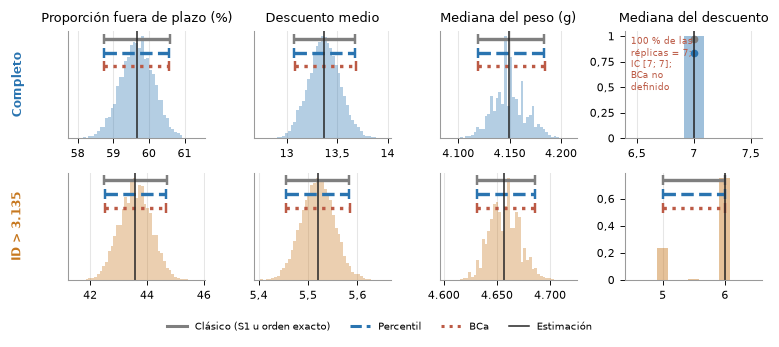

In [8]:
PANELES = ["Proporción fuera de plazo", "Descuento medio", "Mediana del peso", "Mediana del descuento"]
fig, axes = plt.subplots(2, 4, figsize=(7.2, 3.0))
for i, conj in enumerate(CONJUNTOS):
    for j, par in enumerate(PANELES):
        ax = axes[i, j]
        r = REPS[(conj, par)]
        f = tab_boot.query("conjunto == @conj and parametro == @par").iloc[0]
        esc = 100 if par.startswith("Proporción") else 1
        vals = np.unique(r)
        if len(vals) <= 12:   # distribución discreta: barras por valor
            frec = pd.Series(r).value_counts(normalize=True).sort_index()
            ax.bar(frec.index * esc, frec.values, width=0.18, color=COLOR_CONJ[conj], alpha=0.45)
            ax.set_xlim(vals.min() - 0.6, vals.max() + 0.6)
            ax.set_ylabel("Proporción" if j == 0 else "")
        else:
            ax.hist(r * esc, bins=45, color=COLOR_CONJ[conj], alpha=0.35, density=True)
            ax.set_yticks([])
        ymax = ax.get_ylim()[1]
        for (lo, hi), col, ls, y in [((f.clasico_inf, f.clasico_sup), C_CLASICO, "-", 0.93),
                                      ((f.percentil_inf, f.percentil_sup), C_PERC, "--", 0.80),
                                      ((f.bca_inf, f.bca_sup), C_BCA, ":", 0.67)]:
            if np.isfinite(lo) and hi > lo:
                ax.plot([lo * esc, hi * esc], [y * ymax] * 2, color=col, ls=ls, lw=2.2, solid_capstyle="butt")
                ax.plot([lo * esc, hi * esc], [y * ymax] * 2, "|", color=col, ms=6.0, mew=1.6)
            elif np.isfinite(lo):           # IC de amplitud cero: un punto
                ax.plot([lo * esc], [y * ymax], "o", color=col, ms=4)
        ax.axvline(f.estimacion * esc, color="#262626", lw=1)
        if f.bca_estado == "no definido":
            ax.text(0.04, 0.45, "100 % de las\nréplicas = 7;\nIC [7; 7];\nBCa no\ndefinido", transform=ax.transAxes,
                    ha="left", fontsize=6.0, color=C_BCA)
        unidad = {"Proporción fuera de plazo": " (%)", "Mediana del peso": " (g)"}.get(par, "")
        ax.set_title(f"{par}{unidad}" if i == 0 else "")
        ax.grid(axis="y", visible=False)
    axes[i, 0].annotate(conj, xy=(-0.42, 0.5), xycoords="axes fraction", rotation=90, va="center",
                        fontsize=8.0, fontweight="bold", color=COLOR_CONJ[conj])
leyenda = [Line2D([0], [0], color=C_CLASICO, lw=2, label="Clásico (S1 u orden exacto)"),
           Line2D([0], [0], color=C_PERC, lw=2, ls="--", label="Percentil"),
           Line2D([0], [0], color=C_BCA, lw=2, ls=":", label="BCa"),
           Line2D([0], [0], color="#262626", lw=1, label="Estimación")]
fig.legend(handles=leyenda, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0.02, 0.04, 1, 1))
guardar_figura(fig, "s2_fig01_bootstrap_ic")
plt.show()

### 1.7 Interpretación

**Medias y proporción (8 intervalos).** Los tres métodos coinciden: la razón de amplitudes percentil/clásico está entre 0,98 y 1,01, el centro del BCa se desplaza menos de 0,06 errores estándar respecto del clásico, y |z0| ≤ 0,011 y |a| ≤ 0,003. Incluso el descuento, la variable más asimétrica de S1 (asimetría 1,80), tiene una distribución bootstrap de la media prácticamente simétrica (asimetría 0,04): con n = 10.999, el TCL compensa la asimetría de los datos. **Los intervalos de S1 quedan validados**, y la aproximación normal elegida en S1 era adecuada.

**Medianas (pedidas por el docente).** La mediana del peso, 4.149 g [4.119; 4.183], coincide exactamente con el intervalo por estadísticos de orden; la variante BC da [4.119; 4.184]. Supera en 515 g a la media porque el peso es bimodal y la media cae en la zona de menor densidad. En ID > 3.135 la mediana sube a 4.657 g [4.631; 4.686]. La mediana del descuento muestra un límite del método: en el conjunto completo las 10.000 réplicas valen 7, el intervalo percentil es [7; 7] y BCa no está definido. Eso no expresa certeza absoluta, sino que el estimador es discreto: el valor 7 concentra tanta masa que ninguna remuestra desplaza el centro. El bootstrap suavizado da [6,96; 7,21]. En el subconjunto la distribución bootstrap se reparte entre 6 (75,4 %) y 5 (23,9 %), y el intervalo suavizado, [5,43; 5,65], queda bajo 6: estima la mediana de la variable continua subyacente (antes del redondeo al entero), no la mediana entera, por lo que se informa como complemento y no como reemplazo.

**Dónde está la discrepancia real.** No entre métodos, sino entre conjuntos: el descuento medio pasa de 13,37 a 5,52 y la mediana del peso de 4.149 a 4.657 g, con intervalos que no se solapan. El bootstrap confirma que los IC de S1 describen bien el archivo; no confirma que el archivo represente una sola población. Esa pregunta se aborda en la sección 5.

## 2. Validación de las pruebas de hipótesis de S1 mediante permutación

### 2.1 Lógica de la prueba

Bajo la hipótesis nula de que el cumplimiento no se asocia con la variable estudiada, las etiquetas «fuera de plazo / a tiempo» son **intercambiables**: cualquier reasignación de esas etiquetas entre los envíos es igualmente probable. La prueba de permutación reasigna las etiquetas al azar B veces (manteniendo el número de envíos fuera de plazo), recalcula el estadístico y compara el valor observado con esa distribución nula construida sin supuestos distribucionales (Good, 2005):

$$p = \frac{\#\{|T^*_b| \ge |T_{\text{obs}}|\} + 1}{B + 1}$$

El «+1» incluye la asignación observada y evita valores p iguales a cero; por eso con B = 10.000 el menor valor p posible es 1/10.001 ≈ 0,0001. El error estándar Monte Carlo del valor p es $\sqrt{p(1-p)/B}$.

**Pruebas validadas (4 × 2 conjuntos):**

| Prueba | Estadístico | Origen |
|---|---|---|
| Peso según cumplimiento | t de Welch (estudentizado) | S1, Prueba 1 (Tabla 12) |
| Importancia × cumplimiento | χ² de independencia (cola superior) | S1, Prueba 2 (Tabla 14) |
| Importancia alta frente al resto | z de dos proporciones | S1, contraste complementario (Tabla 15) |
| Peso según cumplimiento | Diferencia de **medianas** | Nueva, sugerida por el docente; referencia clásica: prueba de la mediana de Mood |

**Por qué el estadístico estudentizado.** La permutación prueba la igualdad de las distribuciones completas, no solo de las medias. Si las varianzas difieren, permutar la diferencia de medias cruda puede rechazar por diferencias de dispersión. Usar el t de Welch como estadístico mantiene la validez asintótica para la hipótesis de igualdad de medias aun con varianzas distintas (Chung y Romano, 2013). En S1, Levene detectó varianzas distintas en el conjunto completo (p < 0,001), por lo que esta elección no es decorativa.

**Valores p cercanos a 0,05.** En el subconjunto, S1 obtuvo p = 0,065 (Welch), 0,059 (χ²) y 0,036 (z). Con B = 10.000 el error Monte Carlo del valor p es cercano a 0,0024. Para que la decisión no dependa del azar de la simulación, en el subconjunto se repite cada prueba con **100.000 permutaciones** (error Monte Carlo cercano a 0,0007).

In [9]:
def estadisticos_permutacion(Ym, x, onehot, alta):
    # Estadísticos para una matriz de etiquetas Ym (filas = asignaciones; 1 = fuera de plazo).
    Ym = Ym.astype(float)
    n = Ym.shape[1]
    n1 = Ym[0].sum()
    n0 = n - n1
    xc = x - x.mean()                          # centrado para estabilidad numérica
    s1, q1 = Ym @ xc, Ym @ (xc ** 2)
    s0, q0 = xc.sum() - s1, (xc ** 2).sum() - q1
    m1, m0 = s1 / n1, s0 / n0
    v1, v0 = (q1 - n1 * m1 ** 2) / (n1 - 1), (q0 - n0 * m0 ** 2) / (n0 - 1)
    t = (m1 - m0) / np.sqrt(v1 / n1 + v0 / n0)
    # χ² de independencia importancia × cumplimiento.
    nk = onehot.sum(axis=0)
    o1 = Ym @ onehot
    o0 = nk - o1
    e1, e0 = nk * n1 / n, nk * n0 / n
    chi2 = ((o1 - e1) ** 2 / e1 + (o0 - e0) ** 2 / e0).sum(axis=1)
    # z de dos proporciones: importancia alta frente al resto.
    na = alta.sum()
    x1 = Ym @ alta
    p1, p0, pc = x1 / na, (n1 - x1) / (n - na), n1 / n
    z = (p1 - p0) / np.sqrt(pc * (1 - pc) * (1 / na + 1 / (n - na)))
    # Diferencia de medianas del peso (fuera de plazo − a tiempo).
    xm1 = np.where(Ym == 1, x, np.nan)
    xm0 = np.where(Ym == 0, x, np.nan)
    dmed = np.nanmedian(xm1, axis=1) - np.nanmedian(xm0, axis=1)
    return {"t_welch": t, "chi2": chi2, "z_alta": z, "dif_mediana": dmed}


def prueba_permutacion(d, B, rng, lote=LOTE):
    y = d[Y].to_numpy()
    x = d["Weight_in_gms"].to_numpy(dtype=float)
    onehot = pd.get_dummies(d["Product_importance"])[["low", "medium", "high"]].to_numpy(dtype=float)
    alta = (d["Product_importance"] == "high").to_numpy(dtype=float)
    obs = {k: v[0] for k, v in estadisticos_permutacion(y[None, :], x, onehot, alta).items()}
    nulas = {k: np.empty(B) for k in obs}
    for ini in range(0, B, lote):
        m = min(lote, B - ini)
        Ym = rng.permuted(np.tile(y, (m, 1)), axis=1)
        for k, v in estadisticos_permutacion(Ym, x, onehot, alta).items():
            nulas[k][ini:ini + m] = v
    return obs, nulas


def valor_p(obs, nula, dos_colas=True):
    tol = 1e-9 * max(1.0, abs(obs))
    extremos = np.abs(nula) >= abs(obs) - tol if dos_colas else nula >= obs - tol
    p = (extremos.sum() + 1) / (len(nula) + 1)
    return p, np.sqrt(p * (1 - p) / len(nula))


DOS_COLAS = {"t_welch": True, "chi2": False, "z_alta": True, "dif_mediana": True}
print("Funciones de permutación listas.")

Funciones de permutación listas.


In [10]:
rng = np.random.default_rng(SEED)      # sección 2: generador reiniciado

OBS, NULAS, NULAS_FINAS = {}, {}, {}
for conj, d in CONJUNTOS.items():
    OBS[conj], NULAS[conj] = prueba_permutacion(d, B_PERM, rng)
for conj in ["ID > 3.135"]:            # refinamiento donde S1 obtuvo p cercanos a 0,05
    _, NULAS_FINAS[conj] = prueba_permutacion(CONJUNTOS[conj], B_PERM_FINO, rng)

# Coherencia con S1: los estadísticos observados deben ser los mismos.
assert np.isclose(OBS["Completo"]["t_welch"], float(w1["t"])) and np.isclose(OBS["ID > 3.135"]["t_welch"], float(w1s["t"]))
assert np.isclose(OBS["Completo"]["chi2"], float(c2["chi2"])) and np.isclose(OBS["ID > 3.135"]["chi2"], float(c2s["chi2"]))
assert np.isclose(OBS["Completo"]["z_alta"], t15.loc[0, "estadistico"]) and np.isclose(OBS["ID > 3.135"]["z_alta"], t15.loc[1, "estadistico"])
print("Estadísticos observados idénticos a S1.")

Estadísticos observados idénticos a S1.


In [11]:
# Valores p clásicos: los de S1 y, para la mediana, la prueba de Mood como referencia.
P_CLASICO = {
    ("Completo", "t_welch"): (float(w1["p_valor"]), "Welch (S1 Tabla 12)"),
    ("ID > 3.135", "t_welch"): (float(w1s["p_valor"]), "Welch (S1 Tabla 12b)"),
    ("Completo", "chi2"): (float(c2["p_valor"]), "χ² (S1 Tabla 14)"),
    ("ID > 3.135", "chi2"): (float(c2s["p_valor"]), "χ² (S1 Tabla 14b)"),
    ("Completo", "z_alta"): (t15.loc[0, "p_valor"], "z (S1 Tabla 15)"),
    ("ID > 3.135", "z_alta"): (t15.loc[1, "p_valor"], "z (S1 Tabla 15)"),
}
for conj, d in CONJUNTOS.items():
    mood = stats.median_test(d.loc[d[Y] == 1, "Weight_in_gms"], d.loc[d[Y] == 0, "Weight_in_gms"])
    P_CLASICO[(conj, "dif_mediana")] = (mood.pvalue, "Mood (referencia S2)")

EFECTO = {
    ("Completo", "t_welch"): f"d = {es(float(w1['d_cohen']), 2)}", ("ID > 3.135", "t_welch"): f"d = {es(float(w1s['d_cohen']), 2)}",
    ("Completo", "chi2"): f"V = {es(float(c2['v_cramer']), 3)}", ("ID > 3.135", "chi2"): f"V = {es(float(c2s['v_cramer']), 3)}",
    ("Completo", "z_alta"): f"Δ = {es(t15.loc[0, 'diferencia_pp'], 2)} pp", ("ID > 3.135", "z_alta"): f"Δ = {es(t15.loc[1, 'diferencia_pp'], 2)} pp",
}
NOMBRE_PRUEBA = {"t_welch": "Peso: t de Welch", "chi2": "Importancia: χ²",
                 "z_alta": "Alta vs. resto: z", "dif_mediana": "Peso: diferencia de medianas"}

filas = []
for conj in CONJUNTOS:
    for k in NOMBRE_PRUEBA:
        p, se = valor_p(OBS[conj][k], NULAS[conj][k], DOS_COLAS[k])
        p_cl, origen = P_CLASICO[(conj, k)]
        fila = {"conjunto": conj, "prueba": NOMBRE_PRUEBA[k], "estadistico_obs": OBS[conj][k],
                "p_clasico": p_cl, "origen_p_clasico": origen, "p_perm_10k": p, "ee_mc_10k": se,
                "efecto": EFECTO.get((conj, k), f"Δ mediana = {es(OBS[conj][k], 0)} g")}
        if conj in NULAS_FINAS:
            p2, se2 = valor_p(OBS[conj][k], NULAS_FINAS[conj][k], DOS_COLAS[k])
            fila.update({"p_perm_100k": p2, "ee_mc_100k": se2})
        filas.append(fila)
tab_perm = pd.DataFrame(filas)
tab_perm["p_perm_final"] = tab_perm["p_perm_100k"].fillna(tab_perm["p_perm_10k"])
tab_perm["en_cota_resolucion"] = tab_perm["p_perm_final"] <= 1 / (B_PERM + 1) + 1e-12
tab_perm["decision_clasica"] = np.where(tab_perm["p_clasico"] < ALFA, "Rechaza H0", "No rechaza H0")
tab_perm["decision_perm"] = np.where(tab_perm["p_perm_final"] < ALFA, "Rechaza H0", "No rechaza H0")
tab_perm["concordancia"] = np.where(tab_perm["decision_clasica"] == tab_perm["decision_perm"], "Concuerda", "Discrepa")

# Holm sobre la familia de pruebas del subconjunto (análisis de sensibilidad exploratorio).
msk = tab_perm["conjunto"] == "ID > 3.135"
orden = tab_perm.loc[msk, "p_perm_final"].sort_values()
m = len(orden)
holm = np.maximum.accumulate([(m - i) * p for i, p in enumerate(orden.values)]).clip(max=1)
tab_perm.loc[orden.index, "p_holm_subconjunto"] = holm
guardar_tabla(tab_perm, "s2_tab02_permutacion")
with pd.option_context("display.float_format", "{:.5f}".format):
    display(tab_perm[["conjunto", "prueba", "estadistico_obs", "p_clasico", "p_perm_10k", "ee_mc_10k",
                      "p_perm_100k", "p_holm_subconjunto", "efecto", "concordancia"]])

,conjunto,prueba,estadistico_obs,p_clasico,p_perm_10k,ee_mc_10k,p_perm_100k,p_holm_subconjunto,efecto,concordancia
0,Completo,Peso: t de Welch,-29.27223,0.00000,0.00010,0.00010,NaN,NaN,"d = −0,57",Concuerda
1,Completo,Importancia: χ²,12.21116,0.00223,0.00240,0.00049,NaN,NaN,"V = 0,033",Concuerda
2,Completo,Alta vs. resto: z,3.48629,0.00049,0.00070,0.00026,NaN,NaN,"Δ = 5,81 pp",Concuerda
3,Completo,Peso: diferencia de medianas,-1443.00000,0.00000,0.00010,0.00010,NaN,NaN,Δ mediana = −1.443 g,Concuerda
4,ID > 3.135,Peso: t de Welch,-1.84894,0.06451,0.06379,0.00244,0.06381,0.17790,"d = −0,04",Concuerda
5,ID > 3.135,Importancia: χ²,5.64369,0.05950,0.05909,0.00236,0.05930,0.17790,"V = 0,027",Concuerda
6,ID > 3.135,Alta vs. resto: z,2.09546,0.03613,0.03890,0.00193,0.03570,0.14280,"Δ = 4,31 pp",Concuerda
7,ID > 3.135,Peso: diferencia de medianas,-38.00000,0.21835,0.18468,0.00388,0.18039,0.18039,Δ mediana = −38 g,Concuerda


### 2.2 Distribuciones nulas

Cada panel muestra la distribución del estadístico bajo permutación (B = 10.000), la referencia asintótica que usó S1 (normal estándar para t y z, χ² con 2 grados de libertad) y el valor observado. En el conjunto completo los valores observados de las pruebas del peso quedan muy lejos de la distribución nula; se indican con una flecha en el borde del panel.

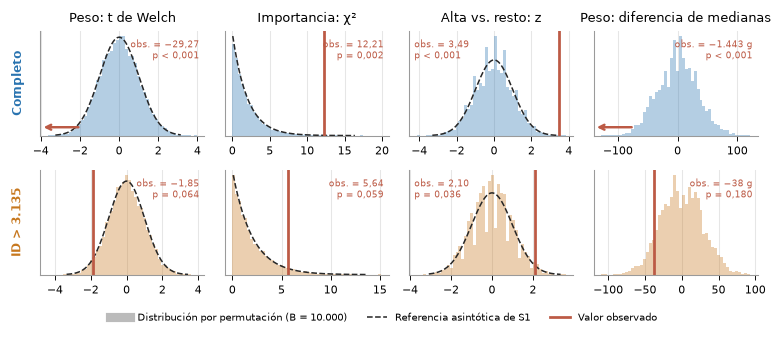

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(7.2, 2.95))
for i, conj in enumerate(CONJUNTOS):
    for j, k in enumerate(NOMBRE_PRUEBA):
        ax = axes[i, j]
        nula, obs = NULAS[conj][k], OBS[conj][k]
        ax.hist(nula, bins=50, density=True, color=COLOR_CONJ[conj], alpha=0.35)
        lo, hi = np.percentile(nula, [0.05, 99.95])
        grid = np.linspace(min(lo, 0), hi, 300) if k == "chi2" else np.linspace(lo, hi, 300)
        if k in ("t_welch", "z_alta"):
            ax.plot(grid, stats.norm.pdf(grid), color="#262626", lw=1, ls="--")
        elif k == "chi2":
            g = grid[grid > 0.05]
            ax.plot(g, stats.chi2.pdf(g, 2), color="#262626", lw=1, ls="--")
        xmin, xmax = ax.get_xlim()
        fila = tab_perm.query("conjunto == @conj and prueba == @NOMBRE_PRUEBA[@k]").iloc[0]
        etiqueta = f"obs. = {es(obs, 2)}" if k != "dif_mediana" else f"obs. = {es(obs, 0)} g"
        texto_p = "p < 0,001" if fila.p_perm_final < 0.001 else f"p = {es(fila.p_perm_final, 3)}"
        if xmin <= obs <= xmax:
            ax.axvline(obs, color=C_BCA, lw=1.8)
        else:
            borde = xmin if obs < xmin else xmax
            ax.annotate("", xy=(borde, 0.08 * ax.get_ylim()[1]), xytext=(borde + (0.25 if obs > xmax else -0.25) * (xmin - xmax), 0.08 * ax.get_ylim()[1]),
                        arrowprops=dict(arrowstyle="->", color=C_BCA, lw=1.6))
        izquierda = k == "z_alta"
        ax.text(0.03 if izquierda else 0.97, 0.93, f"{etiqueta}\n{texto_p}", transform=ax.transAxes,
                ha="left" if izquierda else "right", va="top", fontsize=6.0, color=C_BCA)
        ax.set_yticks([])
        ax.grid(axis="y", visible=False)
        if i == 0:
            ax.set_title(NOMBRE_PRUEBA[k])
    axes[i, 0].annotate(conj, xy=(-0.18, 0.5), xycoords="axes fraction", rotation=90, va="center",
                        fontsize=8.0, fontweight="bold", color=COLOR_CONJ[conj])
leyenda = [Line2D([0], [0], color="#BBBBBB", lw=6, label="Distribución por permutación (B = 10.000)"),
           Line2D([0], [0], color="#262626", lw=1, ls="--", label="Referencia asintótica de S1"),
           Line2D([0], [0], color=C_BCA, lw=1.8, label="Valor observado")]
fig.legend(handles=leyenda, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.03))
fig.tight_layout(rect=(0.02, 0.04, 1, 1))
guardar_figura(fig, "s2_fig02_permutacion")
plt.show()

### 2.3 Interpretación

**Concordancia.** Las ocho comparaciones llegan a la misma decisión con la prueba clásica y con la permutación. En el conjunto completo, Welch y la diferencia de medianas quedan en la cota de resolución (p = 1/10.001), y χ² y z prácticamente reproducen los valores de S1 (0,0024 frente a 0,0022; 0,0007 frente a 0,0005). En el subconjunto, con 100.000 permutaciones: Welch 0,0638 (S1: 0,0645), χ² 0,0593 (0,0595), z 0,0357 (0,0361) y diferencia de medianas 0,180 (Mood: 0,218). Con un error Monte Carlo cercano a 0,0007, ninguna decisión depende del azar de la simulación. Las densidades asintóticas superpuestas en el gráfico anterior coinciden con las distribuciones por permutación: con estos tamaños muestrales, las aproximaciones paramétricas de S1 son exactas a efectos prácticos.

**Robustez de los resultados.** La permutación no cambia ninguna conclusión de S1; lo que las cambia es el bloque inicial, como ya mostró S1. Dos matices agregan información nueva:

- La diferencia de medianas del peso (−1.443 g en el completo) es aún mayor que la de medias, pero en el subconjunto cae a −38 g (p = 0,180): la desaparición del efecto del peso no depende de usar medias.
- En el subconjunto, el contraste z es el único nominalmente significativo, pero no resiste la corrección de Holm. La familia incluye las cuatro pruebas del subconjunto, una elección conservadora porque Welch y medianas miden el mismo efecto y z es un contraste dentro del χ²; con solo las tres pruebas de S1, el p ajustado de z sería 3 × 0,0357 = 0,107, y la conclusión no cambia. Se mantiene como **señal exploratoria**, no como asociación confirmada.

## 3. Estabilidad de las correlaciones de S1

S1 resumió la asociación de cada variable numérica con el retraso mediante el ρ de Spearman (Tabla 5), elegido por la asimetría y la naturaleza ordinal de varias variables. Aquí se evalúa la **estabilidad** de las cinco correlaciones con |ρ| > 0,05 en S1 (descuento, peso, compras previas, costo y llamadas) con un intervalo bootstrap percentil al 95 % (B = 10.000), en los dos conjuntos. En cada remuestra se vuelven a calcular los rangos, de modo que el intervalo refleja también la variabilidad del ordenamiento con empates.

**Criterios de clasificación.** Se combinan dirección, significancia y magnitud, porque con n cercano a 10.000 una correlación muy pequeña puede excluir el 0 sin tener relevancia práctica:

| Estado | Criterio |
|---|---|
| Estable | El IC excluye el 0 en ambos conjuntos, con el mismo signo, y |ρ| en ID > 3.135 conserva al menos la mitad del valor del conjunto completo |
| Atenuada | Mismo signo y el IC excluye el 0 en ambos conjuntos, pero |ρ| cae más de la mitad en ID > 3.135 |
| Dependiente del bloque | El IC excluye el 0 en el conjunto completo, pero incluye el 0 en ID > 3.135 |
| Invierte el signo | Los IC excluyen el 0 en ambos conjuntos, con signos opuestos |
| Nula | El IC incluye el 0 en ambos conjuntos |

In [13]:
rng = np.random.default_rng(SEED)      # sección 3: generador reiniciado

VARS_CORR = {"Discount_offered": "Descuento", "Weight_in_gms": "Peso", "Prior_purchases": "Compras previas",
             "Cost_of_the_Product": "Costo", "Customer_care_calls": "Llamadas"}


def spearman_filas(A, B):
    # ρ de Spearman fila a fila: correlación de Pearson entre rangos (empates promediados).
    ra, rb = stats.rankdata(A, axis=1), stats.rankdata(B, axis=1)
    ra -= ra.mean(axis=1, keepdims=True)
    rb -= rb.mean(axis=1, keepdims=True)
    return (ra * rb).sum(axis=1) / np.sqrt((ra ** 2).sum(axis=1) * (rb ** 2).sum(axis=1))


filas, REPS_CORR = [], {}
for conj, d in CONJUNTOS.items():
    y = d[Y].to_numpy(dtype=float)
    X = {v: d[v].to_numpy(dtype=float) for v in VARS_CORR}
    reps = {v: np.empty(B_BOOT) for v in VARS_CORR}
    n = len(y)
    for ini in range(0, B_BOOT, LOTE):     # mismas remuestras para las cinco variables
        m = min(LOTE, B_BOOT - ini)
        idx = rng.integers(0, n, size=(m, n))
        Yb = y[idx]
        for v in VARS_CORR:
            reps[v][ini:ini + m] = spearman_filas(X[v][idx], Yb)
    for v, etiqueta in VARS_CORR.items():
        rho = stats.spearmanr(X[v], y)[0]
        lo, hi = np.percentile(reps[v], [2.5, 97.5])
        REPS_CORR[(conj, etiqueta)] = reps[v]
        filas.append({"conjunto": conj, "variable": etiqueta, "rho": rho, "ic_inf": lo, "ic_sup": hi,
                      "se_bootstrap": reps[v].std(ddof=1), "excluye_cero": (lo > 0) or (hi < 0)})

tab_corr = pd.DataFrame(filas)
# Coherencia con S1 en el conjunto completo.
for v, etiqueta in VARS_CORR.items():
    assert np.isclose(tab_corr.query("conjunto == 'Completo' and variable == @etiqueta")["rho"].iloc[0], t05.loc[v, "spearman"])


def clasificar(c, s):
    if c.excluye_cero and s.excluye_cero:
        if np.sign(c.rho) != np.sign(s.rho):
            return "Invierte el signo"
        return "Estable" if abs(s.rho) >= 0.5 * abs(c.rho) else "Atenuada"
    if c.excluye_cero:
        return "Dependiente del bloque"
    if s.excluye_cero:
        return "Solo en el subconjunto"
    return "Nula"


estado = {}
for etiqueta in VARS_CORR.values():
    c = tab_corr.query("conjunto == 'Completo' and variable == @etiqueta").iloc[0]
    s = tab_corr.query("conjunto == 'ID > 3.135' and variable == @etiqueta").iloc[0]
    estado[etiqueta] = clasificar(c, s)
tab_corr["estado"] = tab_corr["variable"].map(estado)
rc = tab_corr.pivot(index="variable", columns="conjunto", values="rho").abs()
tab_corr["cambio_magnitud_pct"] = tab_corr["variable"].map(100 * (rc["ID > 3.135"] - rc["Completo"]) / rc["Completo"])
guardar_tabla(tab_corr, "s2_tab03_correlaciones_bootstrap")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(tab_corr)

,conjunto,variable,rho,ic_inf,ic_sup,se_bootstrap,excluye_cero,estado,cambio_magnitud_pct
0,Completo,Descuento,0.3351,0.3187,0.3511,0.0084,True,Dependiente del bloque,-96.9440
1,Completo,Peso,-0.2660,-0.2838,-0.2478,0.0092,True,Atenuada,-91.4466
2,Completo,Compras previas,-0.0746,-0.0935,-0.0560,0.0096,True,Dependiente del bloque,-90.2414
3,Completo,Costo,-0.0719,-0.0903,-0.0534,0.0094,True,Invierte el signo,-52.2038
4,Completo,Llamadas,-0.0643,-0.0825,-0.0457,0.0094,True,Invierte el signo,-59.2067
5,ID > 3.135,Descuento,-0.0102,-0.0322,0.0122,0.0113,False,Dependiente del bloque,-96.9440
6,ID > 3.135,Peso,-0.0227,-0.0451,-0.0003,0.0112,True,Atenuada,-91.4466
7,ID > 3.135,Compras previas,0.0073,-0.0151,0.0297,0.0113,False,Dependiente del bloque,-90.2414
8,ID > 3.135,Costo,0.0343,0.0116,0.0560,0.0113,True,Invierte el signo,-52.2038
9,ID > 3.135,Llamadas,0.0262,0.0042,0.0476,0.0112,True,Invierte el signo,-59.2067


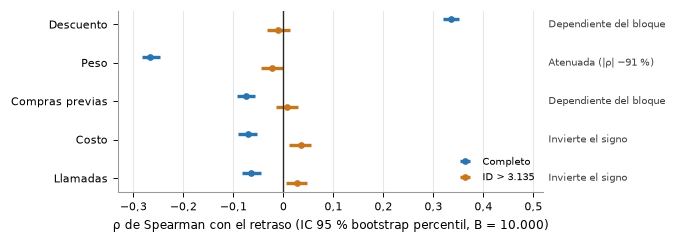

In [14]:
fig, ax = plt.subplots(figsize=(6.2, 2.25))
etiquetas = list(VARS_CORR.values())
for k, conj in enumerate(CONJUNTOS):
    t = tab_corr[tab_corr["conjunto"] == conj].set_index("variable").loc[etiquetas]
    ypos = np.arange(len(etiquetas))[::-1] + (0.14 if k == 0 else -0.14)
    ax.errorbar(t["rho"], ypos, xerr=[t["rho"] - t["ic_inf"], t["ic_sup"] - t["rho"]], fmt="o", ms=3.4,
                color=COLOR_CONJ[conj], ecolor=COLOR_CONJ[conj], elinewidth=2.2, capsize=0, label=conj)
ax.axvline(0, color="#262626", lw=0.9)
ax.set_yticks(np.arange(len(etiquetas))[::-1])
ax.set_yticklabels(etiquetas)
ax.set_xlabel("ρ de Spearman con el retraso (IC 95 % bootstrap percentil, B = 10.000)")
ax.set_xlim(-0.33, 0.52)
for yv, et in zip(np.arange(len(etiquetas))[::-1], etiquetas):
    cambio = tab_corr.query("variable == @et")["cambio_magnitud_pct"].iloc[0]
    texto = f"{estado[et]} (|ρ| {es(cambio, 0)} %)" if estado[et] == "Atenuada" else estado[et]
    ax.text(0.53, yv, texto, va="center", fontsize=6.5, color="#404040")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", ncol=1, bbox_to_anchor=(1.0, 0.0))
fig.tight_layout()
guardar_figura(fig, "s2_fig03_correlaciones")
plt.show()

### 3.1 Interpretación

Ninguna de las cinco correlaciones es estable. La más fuerte de S1, la del **descuento** (0,335 [0,319; 0,351]), desaparece en ID > 3.135 (−0,010 [−0,032; 0,012]). El **peso** conserva el signo, pero su magnitud cae 91 % (−0,266 → −0,023 [−0,045; −0,000]). Las **compras previas** pasan de −0,075 a 0,007, con un IC que incluye el 0. El **costo** (−0,072 → 0,034) y las **llamadas** (−0,064 → 0,026) invierten el signo con intervalos que excluyen el 0 en ambos conjuntos: es un efecto de composición, análogo a la paradoja de Simpson que S1 documentó para las llamadas (Tabla 17).

Los errores estándar bootstrap (0,008 a 0,011) suponen envíos independientes. En el subconjunto ese supuesto es plausible (sección 5.2), por lo que allí los intervalos son confiables; en el conjunto completo, el bootstrap por bloques de la sección 5.2 muestra cuánto se ensanchan cuando se respeta el orden del archivo. Para S3, ninguna de estas correlaciones justifica por sí sola incluir una variable en el modelo.

## 4. Simulación Monte Carlo basada en parámetros de S1

### 4.1 Problema y modelo

S1 estimó la proporción de envíos fuera de plazo con un intervalo de 95 % de ancho aproximado de ±0,9 puntos porcentuales. Ese intervalo describe la incertidumbre sobre el **parámetro**, no lo que ocurrirá en un lote concreto de envíos. La pregunta operativa es otra: **en un lote de N envíos, ¿cuántos retrasos cabe esperar, con qué dispersión y con qué probabilidad el lote supera lo que S1 consideró plausible?** También interesa cuánto cambiaría el resultado si se actuara sobre el único segmento con una señal en ambos conjuntos en S1: los productos de importancia alta.

**Modelo generador (por envío).** Cada envío del lote es de importancia alta con probabilidad $w$ y llega fuera de plazo con probabilidad $p_{\text{alta}}$ o $p_{\text{resto}}$ según su segmento. Para propagar la incertidumbre de la estimación de S1, en cada iteración los tres parámetros se extraen de su distribución muestral aproximada, $N(\hat\theta, \widehat{SE}^2)$, truncada a [0, 1] (simulación en dos niveles: parámetro y lote).

**Parámetros: exclusivamente de S1** (Tabla 15 de S1: conteos por segmento en ambos conjuntos). El valor teórico de la tasa esperada, $w\,p_{\text{alta}} + (1-w)\,p_{\text{resto}}$, coincide con la proporción global de S1 y sirve para validar la simulación.

**Umbral de alerta.** Un lote se considera «sobre lo plausible» si su tasa supera el límite superior del intervalo de Wald de S1 (60,59 %). Este umbral permite contrastar la incertidumbre del parámetro con la variabilidad de un lote real.

**Supuestos.** Los envíos son independientes dentro del lote (la sección 5.2 evalúa este supuesto) y la composición del lote replica la del archivo. El modelo no incorpora otras variables porque S1 no encontró asociaciones estables fuera de la importancia; incluirlas sin respaldo sería un error de modelo que más iteraciones no corrigen.

In [15]:
def parametros_s1(fila_t15):
    # Parámetros del modelo desde la Tabla 15 de S1 (conteos por segmento).
    na, nr = fila_t15["n_alta"], fila_t15["n_resto"]
    n = na + nr
    pa, pr, w = fila_t15["retrasos_alta"] / na, fila_t15["retrasos_resto"] / nr, na / n
    return {"p_alta": pa, "se_alta": np.sqrt(pa * (1 - pa) / na), "p_resto": pr, "se_resto": np.sqrt(pr * (1 - pr) / nr),
            "w_alta": w, "se_w": np.sqrt(w * (1 - w) / n), "n": int(n)}


PAR = {"Completo": parametros_s1(t15.loc[0]), "ID > 3.135": parametros_s1(t15.loc[1])}
UMBRAL = t10.loc[0, "ic_superior"]          # límite superior del IC de Wald de S1
tab_par = pd.DataFrame(PAR).T
tab_par["tasa_teorica"] = tab_par["w_alta"] * tab_par["p_alta"] + (1 - tab_par["w_alta"]) * tab_par["p_resto"]
assert np.isclose(tab_par.loc["Completo", "tasa_teorica"], t10.loc[0, "estimacion"])
guardar_tabla(tab_par.reset_index(names="regimen"), "s2_tab04a_parametros_montecarlo")
print(f"Umbral de alerta = {UMBRAL:.4%} (límite superior del IC de Wald, S1 Tabla 10)")
tab_par

Umbral de alerta = 60.5858% (límite superior del IC de Wald, S1 Tabla 10)


,p_alta,se_alta,p_resto,se_resto,w_alta,se_w,n,tasa_teorica
Completo,0.649789,0.015493,0.591682,0.004903,0.086190,0.002676,10999.0,0.596691
ID > 3.135,0.475513,0.019849,0.432444,0.005826,0.080493,0.003068,7864.0,0.435910


In [16]:
def simular_lotes(par, N, B, rng, incertidumbre=True, intervencion=False, max_celdas=2_000_000):
    # Simula B lotes de N envíos. Devuelve tasa del lote, retrasos de importancia alta y, si se
    # pide, los retrasos evitados si la importancia alta tuviera la tasa del resto (mismos números
    # aleatorios en ambos casos: números aleatorios comunes).
    # Los normales estándar del nivel de parámetros se generan siempre (y se multiplican por 0 si
    # no hay incertidumbre), para que escenarios con el mismo N compartan exactamente los mismos
    # números aleatorios.
    tasa, ret_alta, esperada = np.empty(B), np.empty(B), np.empty(B)
    evitados = np.empty(B) if intervencion else None
    tasa_cf = np.empty(B) if intervencion else None
    filas = max(1, max_celdas // N)
    f = 1.0 if incertidumbre else 0.0
    for ini in range(0, B, filas):
        m = min(filas, B - ini)
        za, zr, zw = rng.standard_normal((3, m))
        pa = np.clip(par["p_alta"] + f * par["se_alta"] * za, 0, 1)
        pr = np.clip(par["p_resto"] + f * par["se_resto"] * zr, 0, 1)
        w = np.clip(par["w_alta"] + f * par["se_w"] * zw, 0, 1)
        es_alta = rng.random((m, N)) < w[:, None]
        u = rng.random((m, N))
        tarde = u < np.where(es_alta, pa[:, None], pr[:, None])
        tasa[ini:ini + m] = tarde.mean(axis=1)
        ret_alta[ini:ini + m] = (tarde & es_alta).sum(axis=1)
        esperada[ini:ini + m] = w * pa + (1 - w) * pr        # tasa esperada dado el parámetro
        if intervencion:
            tarde_cf = u < pr[:, None]                         # contrafactual: alta con la tasa del resto
            tasa_cf[ini:ini + m] = tarde_cf.mean(axis=1)
            evitados[ini:ini + m] = tarde.sum(axis=1) - tarde_cf.sum(axis=1)
    return {"tasa": tasa, "ret_alta": ret_alta, "esperada": esperada, "evitados": evitados, "tasa_cf": tasa_cf}


def resumir(sim, N, contrafactual=False):
    t = sim["tasa_cf"] if contrafactual else sim["tasa"]
    out = {"media_tasa": t.mean(), "ee_mc_media": t.std(ddof=1) / np.sqrt(len(t)), "de_tasa": t.std(ddof=1),
           "p2_5": np.percentile(t, 2.5), "p50": np.percentile(t, 50), "p97_5": np.percentile(t, 97.5),
           "p99": np.percentile(t, 99), "prob_sobre_umbral": np.mean(t > UMBRAL),
           "ret_alta_medio": np.nan if contrafactual else sim["ret_alta"].mean()}
    out["ee_mc_prob"] = np.sqrt(out["prob_sobre_umbral"] * (1 - out["prob_sobre_umbral"]) / len(t))
    if contrafactual:
        e = sim["evitados"]
        out.update({"evitados_medio": e.mean(), "evitados_p2_5": np.percentile(e, 2.5), "evitados_p97_5": np.percentile(e, 97.5)})
    return out


# Escenario base: conjunto completo, lote de 1.000 envíos, con incertidumbre de parámetros.
SIM_BASE = simular_lotes(PAR["Completo"], 1000, B_MC, np.random.default_rng(SEED), intervencion=True)
base = resumir(SIM_BASE, 1000)
print(f"Tasa media del lote = {base['media_tasa']:.4%} ± {base['ee_mc_media']:.4%} (EE Monte Carlo) "
      f"· teórico = {tab_par.loc['Completo', 'tasa_teorica']:.4%}")
print(f"Intervalo central 95 % del lote = [{base['p2_5']:.1%}; {base['p97_5']:.1%}] · P99 = {base['p99']:.1%}")
print(f"P(tasa del lote > {UMBRAL:.2%}) = {base['prob_sobre_umbral']:.4f} ± {base['ee_mc_prob']:.4f}")
print(f"Basado en B = {B_MC:,} lotes simulados (semilla = {SEED})")

Tasa media del lote = 59.6723% ± 0.0162% (EE Monte Carlo) · teórico = 59.6691%
Intervalo central 95 % del lote = [56.5%; 62.8%] · P99 = 63.3%
P(tasa del lote > 60.59%) = 0.2946 ± 0.0046
Basado en B = 10,000 lotes simulados (semilla = 42)


### 4.2 Convergencia

Se aplican los diagnósticos del apunte de convergencia: (1) media acumulada frente al valor teórico; (2) error estándar acumulado en escala log-log, que debe decrecer con pendiente −1/2; (3) prueba de Geweke, que compara la media del primer 10 % de las iteraciones con la del último 50 % (Geweke, 1992); y (4) repetición con cinco semillas distintas. La prueba de Geweke fue diseñada para cadenas MCMC, cuyas iteraciones están correlacionadas; aquí las iteraciones son independientes por construcción, de modo que un valor p bajo en una semilla aislada es esperable por azar en alrededor del 5 % de los casos. Por eso se informa en las cinco semillas y se interpreta junto con los demás diagnósticos.

In [17]:
t = SIM_BASE["tasa"]
k = np.arange(1, B_MC + 1)
media_acum = np.cumsum(t) / k
var_acum = (np.cumsum(t ** 2) - k * media_acum ** 2) / np.maximum(k - 1, 1)
ee_acum = np.sqrt(np.maximum(var_acum, 0) / k)
desde = 100
pendiente = np.polyfit(np.log(k[desde:]), np.log(ee_acum[desde:]), 1)[0]
a, b = t[: B_MC // 10], t[B_MC // 2:]
z_geweke = (a.mean() - b.mean()) / np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
p_geweke = 2 * stats.norm.sf(abs(z_geweke))

def geweke(v):
    a, b = v[: len(v) // 10], v[len(v) // 2:]
    zg = (a.mean() - b.mean()) / np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return zg, 2 * stats.norm.sf(abs(zg))


semillas = []
for s_k in range(SEED, SEED + 5):
    sim_k = simular_lotes(PAR["Completo"], 1000, B_MC, np.random.default_rng(s_k))
    r = resumir(sim_k, 1000)
    zg_k, pg_k = geweke(sim_k["tasa"])
    semillas.append({"semilla": s_k, "media_tasa": r["media_tasa"], "ee_mc_media": r["ee_mc_media"],
                     "prob_sobre_umbral": r["prob_sobre_umbral"], "ee_mc_prob": r["ee_mc_prob"],
                     "geweke_z": zg_k, "geweke_p": pg_k})
tab_sem = pd.DataFrame(semillas)
teorico = tab_par.loc["Completo", "tasa_teorica"]
tab_sem["desvio_vs_teorico_en_ee"] = (tab_sem["media_tasa"] - teorico) / tab_sem["ee_mc_media"]
_rb = np.random.default_rng(SEED + 100)   # bootstrap sobre los lotes simulados para el EE del P99
p99_boot = np.array([np.percentile(t[_rb.integers(0, B_MC, B_MC)], 99) for _ in range(1000)])
tab_conv = pd.DataFrame([
    {"diagnostico": "P(sobre umbral), semilla 42", "valor": np.mean(t > UMBRAL)},
    {"diagnostico": "EE Monte Carlo de P(sobre umbral)", "valor": np.sqrt(np.mean(t > UMBRAL) * (1 - np.mean(t > UMBRAL)) / B_MC)},
    {"diagnostico": "P99 de la tasa del lote", "valor": np.percentile(t, 99)},
    {"diagnostico": "EE Monte Carlo del P99 (bootstrap de lotes)", "valor": p99_boot.std(ddof=1)},
    {"diagnostico": "Media final vs. teórico (EE Monte Carlo)", "valor": (media_acum[-1] - teorico) / ee_acum[-1]},
    {"diagnostico": "Pendiente log-log del EE acumulado", "valor": pendiente},
    {"diagnostico": "Geweke z (10 % inicial vs. 50 % final)", "valor": z_geweke},
    {"diagnostico": "Geweke p", "valor": p_geweke},
    {"diagnostico": "Rango de la media entre 5 semillas (pp)", "valor": 100 * np.ptp(tab_sem["media_tasa"])},
    {"diagnostico": "Rango de P(sobre umbral) entre 5 semillas", "valor": np.ptp(tab_sem["prob_sobre_umbral"])},
    {"diagnostico": "Semillas con Geweke p < 0,05 (de 5)", "valor": float((tab_sem["geweke_p"] < 0.05).sum())},
    {"diagnostico": "P(sobre umbral): mínimo entre 5 semillas", "valor": tab_sem["prob_sobre_umbral"].min()},
    {"diagnostico": "P(sobre umbral): máximo entre 5 semillas", "valor": tab_sem["prob_sobre_umbral"].max()},
])
guardar_tabla(tab_conv, "s2_tab04b_convergencia")
guardar_tabla(tab_sem, "s2_tab04c_semillas")
display(tab_conv.style.format({"valor": "{:.4f}"}).hide(axis="index"))
display(tab_sem.style.format("{:.5f}", subset=["media_tasa", "ee_mc_media", "prob_sobre_umbral", "ee_mc_prob", "desvio_vs_teorico_en_ee", "geweke_z", "geweke_p"]).hide(axis="index"))
assert abs(tab_sem["desvio_vs_teorico_en_ee"]).max() < 3.5, "Alguna semilla se aleja del valor teórico más de lo esperable"

diagnostico,valor
"P(sobre umbral), semilla 42",0.2946
EE Monte Carlo de P(sobre umbral),0.0046
P99 de la tasa del lote,0.6330
EE Monte Carlo del P99 (bootstrap de lotes),0.0006
Media final vs. teórico (EE Monte Carlo),0.2034
Pendiente log-log del EE acumulado,-0.4941
Geweke z (10 % inicial vs. 50 % final),2.4043
Geweke p,0.0162
Rango de la media entre 5 semillas (pp),0.0321
Rango de P(sobre umbral) entre 5 semillas,0.0156


semilla,media_tasa,ee_mc_media,prob_sobre_umbral,ee_mc_prob,geweke_z,geweke_p,desvio_vs_teorico_en_ee
42,0.59672,0.00016,0.29460,0.00456,2.40434,0.01620,0.20339
43,0.59645,0.00016,0.28590,0.00452,-1.09959,0.27151,-1.47863
44,0.59664,0.00016,0.29220,0.00455,-0.56641,0.57112,-0.29952
45,0.59676,0.00016,0.29210,0.00455,0.97476,0.32968,0.44896
46,0.59677,0.00016,0.30150,0.00459,0.02153,0.98283,0.50039


### 4.3 Escenarios

Cada escenario reinicia el generador con la misma semilla. Los escenarios con el mismo N comparten exactamente los mismos números aleatorios, por lo que sus diferencias se deben al escenario y no al azar; entre tamaños de lote distintos esto no es posible, porque cambia la cantidad de números por lote:

- **Tamaño del lote:** N = 100, 500, 1.000 y 5.000.
- **Sin incertidumbre de parámetros:** separa la variabilidad propia del lote de la que aporta la estimación de S1.
- **Régimen del subconjunto:** los mismos cálculos con los parámetros de ID > 3.135. Si el bloque inicial no representa la operación habitual, esta es la tasa relevante.
- **Mezcla con el doble de importancia alta.**
- **Intervención hipotética:** la importancia alta con la tasa del resto, con los mismos lotes del escenario base. Es un ejercicio de «qué pasaría si», no una estimación causal.

In [18]:
def escenario(nombre, par, N, **kw):
    sim = simular_lotes(par, N, B_MC, np.random.default_rng(SEED), **kw)
    return {"escenario": nombre, "N": N, **resumir(sim, N)}, sim


par_mezcla = dict(PAR["Completo"], w_alta=2 * PAR["Completo"]["w_alta"])
filas, SIM_N = [], {}
for N in (100, 500, 1000, 5000):
    fila, SIM_N[N] = escenario(f"Completo, N = {es(N, 0)}", PAR["Completo"], N)
    filas.append(fila)
filas.append(escenario("Completo, sin incertidumbre de parámetros", PAR["Completo"], 1000, incertidumbre=False)[0])
fila_sub, SIM_SUB = escenario("Régimen ID > 3.135", PAR["ID > 3.135"], 1000, intervencion=True)
filas.append(fila_sub)
filas.append(escenario("Completo, doble de importancia alta", par_mezcla, 1000)[0])
filas.append({"escenario": "Intervención: alta con tasa del resto (completo)", "N": 1000, **resumir(SIM_BASE, 1000, contrafactual=True)})
fila_sub_cf = resumir(SIM_SUB, 1000, contrafactual=True)
filas.append({"escenario": "Intervención: alta con tasa del resto (ID > 3.135)", "N": 1000, **fila_sub_cf})
tab_esc = guardar_tabla(pd.DataFrame(filas), "s2_tab04d_escenarios")
# Fracción de la varianza del lote atribuible a los parámetros: Var(E[tasa | θ]) / Var(tasa), con los mismos θ simulados,
# y su valor analítico (método delta): w²EE²_alta + (1−w)²EE²_resto + (p_alta − p_resto)²EE²_w sobre la varianza total.
pc0 = PAR["Completo"]
var_par_sim = SIM_N[1000]["esperada"].var(ddof=1)
var_total = SIM_N[1000]["tasa"].var(ddof=1)
var_par_an = (pc0["w_alta"] ** 2 * pc0["se_alta"] ** 2 + (1 - pc0["w_alta"]) ** 2 * pc0["se_resto"] ** 2
              + (pc0["p_alta"] - pc0["p_resto"]) ** 2 * pc0["se_w"] ** 2)
p0 = tab_par.loc["Completo", "tasa_teorica"]
var_lote_an = var_par_an + (p0 * (1 - p0) - var_par_an) / 1000
FRAC_PAR = {"simulada": var_par_sim / var_total, "analitica": var_par_an / var_lote_an}
guardar_tabla(pd.DataFrame([FRAC_PAR]), "s2_tab04i_fraccion_varianza_parametros")
print(f"Fracción de la varianza del lote atribuible a los parámetros (N = 1.000): simulada {FRAC_PAR['simulada']:.1%}, analítica {FRAC_PAR['analitica']:.1%}")
cols = ["escenario", "media_tasa", "de_tasa", "p2_5", "p97_5", "p99", "prob_sobre_umbral", "ret_alta_medio", "evitados_medio", "evitados_p2_5", "evitados_p97_5"]
with pd.option_context("display.float_format", "{:.4f}".format):
    display(tab_esc[cols])

Fracción de la varianza del lote atribuible a los parámetros (N = 1.000): simulada 8.3%, analítica 8.3%


,escenario,media_tasa,de_tasa,p2_5,p97_5,p99,prob_sobre_umbral,ret_alta_medio,evitados_medio,evitados_p2_5,evitados_p97_5
0,"Completo, N = 100",0.5972,0.0491,0.5000,0.6900,0.7100,0.4409,5.5725,NaN,NaN,NaN
1,"Completo, N = 500",0.5972,0.0224,0.5520,0.6400,0.6480,0.3645,27.9428,NaN,NaN,NaN
2,"Completo, N = 1.000",0.5967,0.0162,0.5650,0.6280,0.6330,0.2946,55.8465,NaN,NaN,NaN
3,"Completo, N = 5.000",0.5968,0.0083,0.5806,0.6132,0.6160,0.1353,279.9814,NaN,NaN,NaN
4,"Completo, sin incertidumbre de parámetros",0.5968,0.0156,0.5660,0.6270,0.6330,0.2931,55.9146,NaN,NaN,NaN
5,Régimen ID > 3.135,0.4359,0.0167,0.4040,0.4690,0.4750,0.0000,38.0987,NaN,NaN,NaN
6,"Completo, doble de importancia alta",0.6017,0.0162,0.5700,0.6330,0.6380,0.4120,111.7890,NaN,NaN,NaN
7,Intervención: alta con tasa del resto (completo),0.5918,0.0163,0.5600,0.6240,0.6290,0.2014,NaN,4.9468,1.0000,11.0000
8,Intervención: alta con tasa del resto (ID > 3....,0.4325,0.0168,0.4000,0.4660,0.4710,0.0000,NaN,3.4334,0.0000,9.0000


### 4.4 Datos sintéticos: verificación, fidelidad y comportamiento de los estimadores

El modelo de la sección 4.1 es un **generador de datos sintéticos** (método paramétrico del apunte de datos sintéticos). Se usa en tres pasos:

1. **Verificación de la implementación.** Como el generador usa las tasas de S1 como parámetros, que esas tasas caigan dentro del intervalo central del 95 % de 10.000 archivos sintéticos no prueba fidelidad: comprueba que el código genera lo que se le pide.
2. **Fidelidad** (donde sí se pone a prueba): el peso, generado con dos métodos del curso:
   - *Paramétrico normal:* peso ~ $N(\bar x_g, s_g^2)$ con la media y la desviación por grupo de S1 (Tabla 7).
   - *Perturbación:* peso real del mismo grupo más ruido $N(0, (0{,}1\,s_g)^2)$.

   Se mide con la prueba de Kolmogorov-Smirnov, la distancia de Wasserstein y la fracción de envíos entre 2.000 y 3.999 g, el tramo que S1 asoció al bloque inicial. Con n = 10.999, KS detecta diferencias minúsculas; por eso se interpreta junto con las magnitudes.
3. **Utilidad: potencia del contraste z de S1.** Con archivos sintéticos del tamaño de cada conjunto se estima la probabilidad de detectar (p < 0,05) diferencias de 2 a 6 puntos porcentuales entre importancia alta y el resto, y el tamaño muestral necesario para una potencia de 80 %. No se informa la «potencia observada» al efecto estimado como evidencia, porque es una función directa del valor p (Hoenig y Heisey, 2001). Como control, bajo la hipótesis nula la frecuencia de rechazos debe ser cercana a 5 %.
4. **Comportamiento de los estimadores (sección 4.5):** cobertura empírica de los IC de Wald, percentil y BCa en muestras sintéticas de distintos tamaños.

In [19]:
rng = np.random.default_rng(SEED)      # sección 4.4: generador reiniciado

# (a) Verificación de la implementación (parte binaria): 10.000 archivos sintéticos del tamaño del real.
par, n = PAR["Completo"], len(comp)
na_s = rng.binomial(n, par["w_alta"], B_MC)
xa_s, xr_s = rng.binomial(na_s, par["p_alta"]), rng.binomial(n - na_s, par["p_resto"])
medidas_sint = {"Tasa global": (xa_s + xr_s) / n, "Tasa importancia alta": xa_s / na_s,
                "Tasa resto": xr_s / (n - na_s), "Proporción importancia alta": na_s / n}
real_alta = (comp["Product_importance"] == "high").to_numpy()
medidas_real = {"Tasa global": comp[Y].mean(), "Tasa importancia alta": comp.loc[real_alta, Y].mean(),
                "Tasa resto": comp.loc[~real_alta, Y].mean(), "Proporción importancia alta": real_alta.mean()}
fid_bin = pd.DataFrame([{"medida": m, "real": medidas_real[m], "media_sintetica": v.mean(),
                         "sintetico_p2_5": np.percentile(v, 2.5), "sintetico_p97_5": np.percentile(v, 97.5)}
                        for m, v in medidas_sint.items()])
fid_bin["real_en_intervalo_central"] = (fid_bin["real"] >= fid_bin["sintetico_p2_5"]) & (fid_bin["real"] <= fid_bin["sintetico_p97_5"])

peso_real = comp["Weight_in_gms"].to_numpy(dtype=float)
g = comp[Y].to_numpy()
media_g = t07.query("variable == 'Weight_in_gms' and estadistico == 'mean'")[["A tiempo", "Fuera de plazo"]].iloc[0].to_numpy()
de_g = t07.query("variable == 'Weight_in_gms' and estadistico == 'std'")[["A tiempo", "Fuera de plazo"]].iloc[0].to_numpy()
peso_normal = rng.normal(media_g[g], de_g[g])
peso_pert = peso_real + rng.normal(0, 0.1 * de_g[g])
banda = lambda v: np.mean((v >= 2000) & (v < 4000))
fid_peso = []
for nombre, v in [("Real", peso_real), ("Paramétrico normal", peso_normal), ("Perturbación", peso_pert)]:
    ks = stats.ks_2samp(peso_real, v) if nombre != "Real" else None
    fid_peso.append({"generador": nombre, "media": v.mean(), "de": v.std(ddof=1), "fraccion_2000_3999": banda(v),
                     "ks_D": ks.statistic if ks else np.nan, "ks_p": ks.pvalue if ks else np.nan,
                     "wasserstein_g": stats.wasserstein_distance(peso_real, v) if ks else np.nan})
tab_fid = pd.DataFrame(fid_peso)
PESOS_SINT = {"Real": peso_real, "Paramétrico normal": peso_normal, "Perturbación": peso_pert}
guardar_tabla(fid_bin, "s2_tab04e_verificacion_generador")
guardar_tabla(tab_fid, "s2_tab04f_fidelidad_peso")
display(fid_bin.style.format({"real": "{:.4f}", "media_sintetica": "{:.4f}", "sintetico_p2_5": "{:.4f}", "sintetico_p97_5": "{:.4f}"}).hide(axis="index"))
display(tab_fid.style.format({"media": "{:,.1f}", "de": "{:,.1f}", "fraccion_2000_3999": "{:.3f}", "ks_D": "{:.4f}",
                              "ks_p": "{:.2e}", "wasserstein_g": "{:,.1f}"}).hide(axis="index"))

medida,real,media_sintetica,sintetico_p2_5,sintetico_p97_5,real_en_intervalo_central
Tasa global,0.5967,0.5967,0.5875,0.6058,True
Tasa importancia alta,0.6498,0.6498,0.6193,0.6795,True
Tasa resto,0.5917,0.5917,0.5821,0.6011,True
Proporción importancia alta,0.0862,0.0862,0.0809,0.0915,True


generador,media,de,fraccion_2000_3999,ks_D,ks_p,wasserstein_g
Real,"3,634.0","1,635.4",0.163,nan,nan,nan
Paramétrico normal,"3,622.3","1,634.2",0.430,0.1355,1.72e-88,432.2
Perturbación,"3,633.1","1,641.6",0.185,0.0186,4.33e-02,14.7


In [20]:
def z_sinteticos(par, n, B, rng, dif=None, nula=False):
    # z de dos proporciones en B archivos sintéticos de tamaño n (alta frente al resto).
    # dif: diferencia p_alta − p_resto a simular (manteniendo la tasa global de S1).
    w = par["w_alta"]
    p_glob = w * par["p_alta"] + (1 - w) * par["p_resto"]
    d = 0.0 if nula else (par["p_alta"] - par["p_resto"] if dif is None else dif)
    pr = p_glob - w * d
    pa = pr + d
    na = rng.binomial(n, w, B)
    xa, xr = rng.binomial(na, pa), rng.binomial(n - na, pr)
    p1, p0, pc = xa / na, xr / (n - na), (xa + xr) / n
    return (p1 - p0) / np.sqrt(pc * (1 - pc) * (1 / na + 1 / (n - na)))


def n_para_potencia(par, dif, potencia=0.80):
    # Tamaño total necesario (aproximación normal, asignación w a importancia alta).
    w = par["w_alta"]
    p = w * par["p_alta"] + (1 - w) * par["p_resto"]
    return int(np.ceil((stats.norm.ppf(1 - ALFA / 2) + stats.norm.ppf(potencia)) ** 2 * p * (1 - p) * (1 / w + 1 / (1 - w)) / dif ** 2))


filas = []
for conj in CONJUNTOS:
    par_c, n_c = PAR[conj], PAR[conj]["n"]
    rechazo_h0 = np.mean(np.abs(z_sinteticos(par_c, n_c, B_MC, rng, nula=True)) > Z)
    for dif_pp in (2, 3, 4, 5, 6):
        zs = z_sinteticos(par_c, n_c, B_MC, rng, dif=dif_pp / 100)
        pot = np.mean((np.abs(zs) > Z) & (zs > 0))
        filas.append({"conjunto": conj, "n": n_c, "diferencia_pp": dif_pp, "potencia": pot,
                      "ee_mc": np.sqrt(pot * (1 - pot) / B_MC), "n_para_80": n_para_potencia(par_c, dif_pp / 100),
                      "tasa_rechazo_bajo_H0": rechazo_h0})
tab_pot = guardar_tabla(pd.DataFrame(filas), "s2_tab04g_potencia_sintetica")
dif_s1 = {c: PAR[c]["p_alta"] - PAR[c]["p_resto"] for c in CONJUNTOS}
N80 = {c: n_para_potencia(PAR[c], dif_s1[c]) for c in CONJUNTOS}
guardar_tabla(pd.DataFrame([{"conjunto": c, "n": PAR[c]["n"], "diferencia_pp_S1": 100 * dif_s1[c], "n_para_80": N80[c]} for c in CONJUNTOS]),
              "s2_tab04k_n_potencia_80")
print("Diferencia estimada en S1 (pp):", {c: round(100 * v, 2) for c, v in dif_s1.items()})
print("n necesario para 80 % de potencia con esa diferencia:", N80)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(tab_pot.pivot(index="diferencia_pp", columns="conjunto", values="potencia"))
    display(tab_pot.drop_duplicates("conjunto")[["conjunto", "tasa_rechazo_bajo_H0"]])

Diferencia estimada en S1 (pp): {'Completo': np.float64(5.81), 'ID > 3.135': np.float64(4.31)}
n necesario para 80 % de potencia con esa diferencia: {'Completo': 7103, 'ID > 3.135': 14057}


conjunto,Completo,ID > 3.135
diferencia_pp,,
2,0.2160,0.1677
3,0.4320,0.3080
4,0.6708,0.4920
5,0.8534,0.6825
6,0.9563,0.8333


,conjunto,tasa_rechazo_bajo_H0
0,Completo,0.0530
5,ID > 3.135,0.0497


### 4.5 Comportamiento de los estimadores: cobertura con datos sintéticos

La sección 1 mostró que, con n cercano a 10.000, los IC clásico, percentil y BCa coinciden. ¿Ocurre lo mismo con muestras más pequeñas? Se mide la **cobertura empírica** (fracción de intervalos que contienen el valor verdadero) en 2.000 muestras sintéticas por escenario:

- **Proporción fuera de plazo** con el valor de S1 en ID > 3.135 como verdadero ($p$ = 43,59 %) y n = 30, 100, 500 y 7.864. Para la proporción, el bootstrap de una muestra equivale exactamente a sortear Binomial(n, $\hat p$)/n, lo que permite usar 2.000 remuestras por muestra sin costo.
- **Media del descuento**, la variable más asimétrica, muestreando con reposición la distribución del archivo completo (media verdadera = 13,37) con n = 30, 100 y 500.

Cada intervalo usa 2.000 remuestras. Este estudio es exploratorio: el mínimo de 10.000 se mantiene en todas las validaciones de los resultados de S1.

In [21]:
rng = np.random.default_rng(SEED)      # sección 4.5: generador reiniciado
N_ENSAYOS, B_COB = 2_000, 2_000
zl, zu = stats.norm.ppf([ALFA / 2, 1 - ALFA / 2])


def bca_desde(reps, theta, jack):
    # BCa vectorizado por filas (cada fila, una muestra); devuelve límites o NaN si no está definido.
    prop = (np.sum(reps < theta[:, None], axis=1) + 0.5 * np.sum(reps == theta[:, None], axis=1)) / reps.shape[1]
    dif = jack.mean(axis=1, keepdims=True) - jack
    den = 6 * np.sum(dif ** 2, axis=1) ** 1.5
    ok = (prop > 0) & (prop < 1) & (den > 0)
    z0 = stats.norm.ppf(np.where(ok, prop, 0.5))
    a = np.where(ok, np.sum(dif ** 3, axis=1) / np.where(den > 0, den, 1), 0)
    q1 = stats.norm.cdf(z0 + (z0 + zl) / (1 - a * (z0 + zl)))
    q2 = stats.norm.cdf(z0 + (z0 + zu) / (1 - a * (z0 + zu)))
    lo = np.array([np.percentile(r, 100 * x) for r, x in zip(reps, q1)])
    hi = np.array([np.percentile(r, 100 * x) for r, x in zip(reps, q2)])
    return np.where(ok, lo, np.nan), np.where(ok, hi, np.nan)


filas = []
p_true = sub[Y].mean()
for n in (30, 100, 500, 7864):
    x = rng.binomial(n, p_true, N_ENSAYOS)                 # éxitos por muestra sintética
    ph = x / n
    se = np.sqrt(ph * (1 - ph) / n)
    reps = rng.binomial(n, ph[:, None], (N_ENSAYOS, B_COB)) / n
    # Jackknife de la proporción: (x − 1)/(n − 1) para los x éxitos y x/(n − 1) para los fracasos.
    jack = np.where(np.arange(n)[None, :] < x[:, None], (x[:, None] - 1) / (n - 1), x[:, None] / (n - 1))
    b_lo, b_hi = bca_desde(reps, ph, jack)
    p_lo, p_hi = np.percentile(reps, [2.5, 97.5], axis=1)
    filas.append({"estimador": "Proporción", "n": n,
                  "cobertura_clasico": np.mean((ph - Z * se <= p_true) & (p_true <= ph + Z * se)),
                  "cobertura_percentil": np.mean((p_lo <= p_true) & (p_true <= p_hi)),
                  "cobertura_bca": np.nanmean(((b_lo <= p_true) & (p_true <= b_hi))[~np.isnan(b_lo)]),
                  "bca_no_definido": np.mean(np.isnan(b_lo))})
pobl = comp["Discount_offered"].to_numpy(dtype=float)
mu = pobl.mean()
for n in (30, 100, 500):
    cl = pc_ = bc = 0
    for _ in range(N_ENSAYOS):
        m = rng.choice(pobl, n)
        th = m.mean()
        reps = m[rng.integers(0, n, (B_COB, n))].mean(axis=1)
        se = m.std(ddof=1) / np.sqrt(n)
        tc = stats.t.ppf(0.975, n - 1)
        cl += (th - tc * se <= mu <= th + tc * se)
        lo, hi = np.percentile(reps, [2.5, 97.5])
        pc_ += (lo <= mu <= hi)
        blo, bhi, *_ = bca(reps, th, jackknife_media(m))
        bc += (blo <= mu <= bhi)
    filas.append({"estimador": "Media del descuento", "n": n, "cobertura_clasico": cl / N_ENSAYOS,
                  "cobertura_percentil": pc_ / N_ENSAYOS, "cobertura_bca": bc / N_ENSAYOS, "bca_no_definido": 0.0})
tab_cob = pd.DataFrame(filas)
tab_cob["ee_mc"] = np.sqrt(0.95 * 0.05 / N_ENSAYOS)
guardar_tabla(tab_cob, "s2_tab04j_cobertura_sintetica")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(tab_cob)

,estimador,n,cobertura_clasico,cobertura_percentil,cobertura_bca,bca_no_definido,ee_mc
0,Proporción,30,0.9345,0.9345,0.9575,0.0000,0.0049
1,Proporción,100,0.9450,0.9495,0.9530,0.0000,0.0049
2,Proporción,500,0.9520,0.9520,0.9530,0.0000,0.0049
3,Proporción,7864,0.9455,0.9465,0.9465,0.0000,0.0049
4,Media del descuento,30,0.9165,0.9150,0.9450,0.0000,0.0049
5,Media del descuento,100,0.9365,0.9390,0.9475,0.0000,0.0049
6,Media del descuento,500,0.9405,0.9420,0.9410,0.0000,0.0049


### 4.6 Sensibilidad de la simulación a sus entradas

Diagrama de tornado (análisis local, un parámetro a la vez): cada entrada se lleva a los extremos de su IC al 95 % de S1, manteniendo las demás en su valor base y los mismos números aleatorios, y se registra el cambio en la probabilidad de que un lote de 1.000 envíos supere el umbral. Se agregan el tamaño del lote (N = 500 y 2.000) y el régimen (parámetros de ID > 3.135).

In [22]:
p_base = base["prob_sobre_umbral"]
par0 = PAR["Completo"]
entradas = []
for clave, etiqueta in [("p_alta", "Tasa alta"), ("p_resto", "Tasa resto"), ("w_alta", "Proporción alta")]:
    se = par0["se_" + ("w" if clave == "w_alta" else clave.split("_")[1])]
    vals = []
    for lim in (par0[clave] - Z * se, par0[clave] + Z * se):
        r = resumir(simular_lotes(dict(par0, **{clave: lim}), 1000, B_MC, np.random.default_rng(SEED)), 1000)
        vals.append(r["prob_sobre_umbral"])
    entradas.append({"entrada": f"{etiqueta} (IC S1)", "bajo": vals[0], "alto": vals[1]})
vals = []
for N in (500, 2000):
    vals.append(resumir(simular_lotes(par0, N, B_MC, np.random.default_rng(SEED)), N)["prob_sobre_umbral"])
entradas.append({"entrada": "Lote N = 500 / 2.000", "bajo": vals[0], "alto": vals[1]})
entradas.append({"entrada": "Régimen ID > 3.135", "bajo": fila_sub["prob_sobre_umbral"], "alto": p_base})
tab_tornado = pd.DataFrame(entradas)
tab_tornado["base"] = p_base
tab_tornado["rango"] = (tab_tornado["alto"] - tab_tornado["bajo"]).abs()
tab_tornado = tab_tornado.sort_values("rango")
guardar_tabla(tab_tornado, "s2_tab04h_tornado")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(tab_tornado)

,entrada,bajo,alto,base,rango
2,Proporción alta (IC S1),0.2888,0.3022,0.2946,0.0134
0,Tasa alta (IC S1),0.2423,0.3574,0.2946,0.1151
3,Lote N = 500 / 2.000,0.3645,0.2247,0.2946,0.1398
4,Régimen ID > 3.135,0.0000,0.2946,0.2946,0.2946
1,Tasa resto (IC S1),0.1409,0.5048,0.2946,0.3639


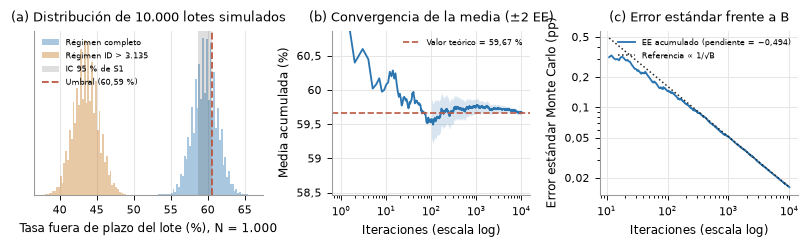

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.3), gridspec_kw={"width_ratios": [1.15, 1, 1]})
ax = axes[0]
bins = np.arange(0.38, 0.66, 0.0025)
ax.hist(SIM_N[1000]["tasa"], bins=bins, color=C_COMPLETO, alpha=0.4, label="Régimen completo")
ax.hist(SIM_SUB["tasa"], bins=bins, color=C_SUB, alpha=0.4, label="Régimen ID > 3.135")
ax.axvspan(t10.loc[0, "ic_inferior"], t10.loc[0, "ic_superior"], color="#262626", alpha=0.15, lw=0, label="IC 95 % de S1")
ax.axvline(UMBRAL, color=C_BCA, lw=1.2, ls="--", label="Umbral (60,59 %)")
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, p: f"{100 * v:.0f}"))
ax.set_xlabel("Tasa fuera de plazo del lote (%), N = 1.000")
ax.set_yticks([]); ax.grid(axis="y", visible=False)
ax.set_title("(a) Distribución de 10.000 lotes simulados")
ax.legend(loc="upper left", fontsize=5.5)
ax = axes[1]
ax.plot(k, 100 * media_acum, color=C_COMPLETO, lw=1.2)
ax.fill_between(k[desde:], 100 * (media_acum - 2 * ee_acum)[desde:], 100 * (media_acum + 2 * ee_acum)[desde:], color=C_COMPLETO, alpha=0.18, lw=0)
ax.axhline(100 * teorico, color=C_BCA, ls="--", lw=1.1, label=f"Valor teórico = {es(100 * teorico, 2)} %")
ax.set_xscale("log"); ax.set_ylim(100 * teorico - 1.2, 100 * teorico + 1.2)
ax.set_xlabel("Iteraciones (escala log)"); ax.set_ylabel("Media acumulada (%)")
ax.set_title("(b) Convergencia de la media (±2 EE)")
ax.legend(loc="upper right", fontsize=5.5)
ax = axes[2]
ax.loglog(k[10:], 100 * ee_acum[10:], color=C_COMPLETO, lw=1.2, label=f"EE acumulado (pendiente = {es(pendiente, 3)})")
ref = 100 * ee_acum[-1] * np.sqrt(B_MC / k[10:])
ax.loglog(k[10:], ref, color="#262626", ls=":", lw=1, label="Referencia ∝ 1/√B")
ax.set_xlabel("Iteraciones (escala log)"); ax.set_ylabel("Error estándar Monte Carlo (pp)")
ax.set_title("(c) Error estándar frente a B")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(_marca_es))
ax.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.yaxis.set_major_locator(matplotlib.ticker.LogLocator(subs=(1.0, 2.0, 5.0)))
ax.legend(loc="upper right", fontsize=5.5)
fig.tight_layout()
guardar_figura(fig, "s2_fig04_montecarlo")
plt.show()

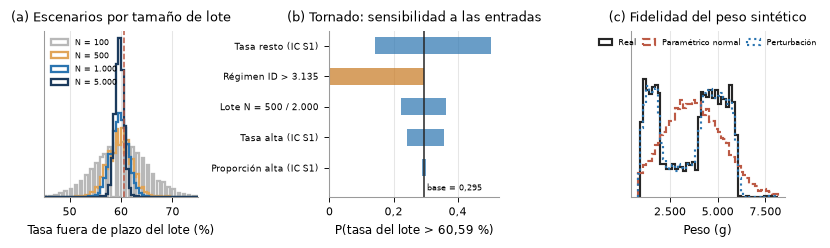

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.3), gridspec_kw={"width_ratios": [1, 1.1, 1]})
ax = axes[0]
for N, col in zip((100, 500, 1000, 5000), ("#B8B8B8", "#E0A458", C_COMPLETO, "#1B3A5C")):
    ax.hist(100 * SIM_N[N]["tasa"], bins=np.arange(40, 80, 0.5), histtype="step", lw=1.5, color=col, density=True,
            label=f"N = {N:,}".replace(",", "."))
ax.axvline(100 * UMBRAL, color=C_BCA, ls="--", lw=1)
ax.set_xlim(45, 75); ax.set_yticks([]); ax.grid(axis="y", visible=False)
ax.set_xlabel("Tasa fuera de plazo del lote (%)")
ax.set_title("(a) Escenarios por tamaño de lote")
ax.legend(fontsize=5.5, loc="upper left")
ax = axes[1]
tt = tab_tornado.reset_index(drop=True)
ypos = np.arange(len(tt))
for i, f in tt.iterrows():
    lo, hi = sorted([f.bajo, f.alto])
    ax.barh(i, hi - lo, left=lo, color=C_COMPLETO if "Régimen" not in f.entrada else C_SUB, alpha=0.7, height=0.55)
ax.axvline(p_base, color="#262626", lw=1)
ax.set_yticks(ypos); ax.set_yticklabels(tt["entrada"], fontsize=6.0)
ax.text(p_base + 0.01, -0.75, f"base = {es(p_base, 3)}", ha="left", fontsize=5.5)
ax.set_ylim(-0.95, len(tt) - 0.5)
ax.set_xlabel("P(tasa del lote > 60,59 %)")
ax.set_title("(b) Tornado: sensibilidad a las entradas")
ax.grid(axis="y", visible=False)
ax = axes[2]
bins = np.arange(800, 8200, 150)
for nombre, col, ls in [("Real", "#262626", "-"), ("Paramétrico normal", C_BCA, "--"), ("Perturbación", C_COMPLETO, ":")]:
    ax.hist(PESOS_SINT[nombre], bins=bins, histtype="step", density=True, color=col, ls=ls, lw=1.4, label=nombre)
ax.set_yticks([]); ax.grid(axis="y", visible=False)
ax.set_xlabel("Peso (g)")
ax.set_title("(c) Fidelidad del peso sintético")
ax.set_ylim(0, ax.get_ylim()[1] * 1.35)
ax.legend(fontsize=5.5, loc="upper center", ncol=3, handlelength=1.5, columnspacing=0.8)
fig.tight_layout()
guardar_figura(fig, "s2_fig05_escenarios_sensibilidad")
plt.show()

### 4.7 Interpretación

**Validez de la simulación.** La media simulada (59,67 % ± 0,016 pp de error estándar Monte Carlo) está a 0,2 errores estándar del valor teórico; el error estándar acumulado decrece con pendiente −0,494, prácticamente la −1/2 esperada; y las cinco semillas quedan dentro de 1,5 errores estándar del valor teórico. La prueba de Geweke da p < 0,05 solo en la semilla base, 42 (z = 2,40): una de cinco, lo esperable por azar con iteraciones independientes. Las cantidades que se usan para decidir también están convergidas: P(lote > umbral) = 0,295 ± 0,005 (entre 0,286 y 0,301 en las cinco semillas) y P99 = 63,3 % ± 0,06 pp.

**Parámetro frente a lote.** El IC de S1 para la proporción es [58,75 %; 60,59 %], pero un lote de 1.000 envíos varía mucho más: su intervalo central del 95 % es [56,5 %; 62,8 %] y casi 3 de cada 10 lotes superan el límite superior del IC de S1 sin que el proceso haya cambiado. La incertidumbre de los parámetros explica 8,3 % de la varianza del lote (igual por simulación y por método delta); el resto es variabilidad binomial propia del lote. Implicancia operativa: un lote con 61–62 % de retrasos no indica deterioro. Para alertas conviene el percentil 99, que depende del tamaño del lote: 71,0 % con N = 100, 63,3 % con N = 1.000 y 61,6 % con N = 5.000.

**Qué domina la incertidumbre.** Con los parámetros del subconjunto, la tasa esperada baja a 43,6 % y ningún lote supera el umbral. La distancia entre regímenes (16 pp) es diez veces la desviación estándar de un lote de 1.000 envíos (1,6 pp). El tornado lo confirma: el régimen y la tasa del resto son las entradas más influyentes; la tasa de la importancia alta tiene un efecto intermedio y su proporción, uno mínimo. Es el «error de modelo» del apunte de convergencia: saber qué régimen representa la operación importa más que cualquier aumento de iteraciones.

**Escenario de decisión.** Con los mismos lotes, si los productos de importancia alta tuvieran la tasa del resto, la tasa media bajaría de 59,7 % a 59,2 %, P(lote > umbral) de 0,295 a 0,201, y se evitarían en promedio 4,9 retrasos por cada 1.000 envíos (intervalo central del 95 %: 1 a 11); en el régimen ID > 3.135, 3,4 (0 a 9). Duplicar la proporción de importancia alta sube la tasa esperada solo 0,5 pp. Priorizar ese segmento tiene un techo de impacto bajo, coherente con la conclusión de S1 de que ninguna variable justifica por sí sola una intervención.

**Datos sintéticos.** Las tasas reales caen dentro del intervalo central de los archivos sintéticos, lo que verifica la implementación del generador. La fidelidad se pone a prueba con el peso: el generador normal con los parámetros de S1 reproduce la media y la desviación (3.622 y 1.634 g frente a 3.634 y 1.635 g) pero no la forma (KS D = 0,135; Wasserstein 432 g; 43,0 % de envíos entre 2.000 y 3.999 g frente a 16,3 % reales), mientras que la perturbación de valores reales la conserva (D = 0,019; 15 g; 18,5 %). La media y la desviación de S1 no bastan para generar ni imputar el peso.

**Potencia.** Con n = 7.864 y la composición del subconjunto, la probabilidad de detectar una diferencia de 4 pp entre importancia alta y el resto es 49 % (68 % para 5 pp); para 80 % de potencia ante la diferencia estimada en S1 (4,3 pp) se necesitarían unos 14.000 envíos. Bajo la hipótesis nula, la frecuencia de rechazos fue 5,30 % y 4,97 %: el generador y la prueba están calibrados. La señal del subconjunto no es concluyente porque el archivo es pequeño para un efecto de ese tamaño.

**Comportamiento de los estimadores.** Para la proporción, los tres IC cubren cerca de 95 % desde n = 100; con n = 30, Wald y percentil caen a 93,5 % y BCa queda más cerca del nominal (95,8 %; la cobertura de una proporción discreta oscila con n). Para la media del descuento, la variable más asimétrica, con n = 30 el IC clásico cubre 91,6 %, el percentil 91,5 % y el BCa 94,5 %; con n = 500 los tres quedan cerca de 94 %. BCa se acerca más al nominal con muestras pequeñas y asimétricas; con muestras de miles, la coincidencia observada en la sección 1 es la esperada, y la aproximación normal de S1 era adecuada.

## 5. Análisis de robustez

Esta sección evalúa la sensibilidad de los resultados de S1 frente a tres amenazas distintas, cada una con su herramienta:

| Amenaza | Pregunta | Herramienta |
|---|---|---|
| Valores atípicos | ¿Una minoría de observaciones extremas mueve las medias y las diferencias? | Media recortada al 5 %, media sin el 1 % superior, mediana y jackknife con influencia máxima |
| Supuesto de independencia | ¿El orden del archivo induce dependencia que los IC de S1 ignoran? | Bootstrap por bloques móviles circulares (Künsch, 1989; Politis y Romano, 1992) |
| Corte elegido después de mirar los datos | ¿Las conclusiones del subconjunto dependen de haber cortado justo en 3.135? | Barrido del corte entre 0 y 6.000 |

El supuesto de normalidad del TCL ya quedó evaluado en la sección 1: la asimetría de las distribuciones bootstrap y los valores de $z_0$ y $a$ cercanos a cero indican que, con n ≥ 7.864, la aproximación normal de S1 es adecuada para medias y proporciones.

### 5.1 Valores atípicos e influencia

In [25]:
def atipicos_iqr(x):
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    return int(np.sum((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)))


filas = []
for conj, d in CONJUNTOS.items():
    for var, etiqueta in [("Cost_of_the_Product", "Costo"), ("Weight_in_gms", "Peso"), ("Discount_offered", "Descuento")]:
        x = d[var].to_numpy(dtype=float)
        n = len(x)
        media = x.mean()
        jack = jackknife_media(x)
        ee_jack = np.sqrt((n - 1) / n * np.sum((jack - jack.mean()) ** 2))
        i_inf = np.argmax(np.abs(jack - media))
        sin_top = x[x <= np.percentile(x, 99)].mean()
        filas.append({"conjunto": conj, "variable": etiqueta, "media": media,
                      "media_recortada_5": stats.trim_mean(x, 0.05), "media_sin_top1": sin_top, "mediana": np.median(x),
                      "cambio_recortada_pct": 100 * (stats.trim_mean(x, 0.05) - media) / media,
                      "cambio_sin_top1_pct": 100 * (sin_top - media) / media,
                      "ee_analitico": x.std(ddof=1) / np.sqrt(n), "ee_jackknife": ee_jack,
                      "valor_mas_influyente": x[i_inf], "influencia_max_en_ee": abs(jack[i_inf] - media) / ee_jack,
                      "atipicos_iqr": atipicos_iqr(x)})
    # Diferencia de peso entre grupos (fuera de plazo − a tiempo) con estimadores robustos.
    p1, p0 = d.loc[d[Y] == 1, "Weight_in_gms"].to_numpy(float), d.loc[d[Y] == 0, "Weight_in_gms"].to_numpy(float)
    filas.append({"conjunto": conj, "variable": "Diferencia de peso (fuera − a tiempo)", "media": p1.mean() - p0.mean(),
                  "media_recortada_5": stats.trim_mean(p1, 0.05) - stats.trim_mean(p0, 0.05),
                  "media_sin_top1": p1[p1 <= np.percentile(p1, 99)].mean() - p0[p0 <= np.percentile(p0, 99)].mean(),
                  "mediana": np.median(p1) - np.median(p0)})
tab_rob = pd.DataFrame(filas)
guardar_tabla(tab_rob, "s2_tab05a_robustez_atipicos")
with pd.option_context("display.float_format", "{:,.3f}".format):
    display(tab_rob)

,conjunto,variable,media,media_recortada_5,media_sin_top1,mediana,cambio_recortada_pct,cambio_sin_top1_pct,ee_analitico,ee_jackknife,valor_mas_influyente,influencia_max_en_ee,atipicos_iqr
0,Completo,Costo,210.197,210.585,209.286,214.000,0.185,-0.433,0.458,0.458,96.000,0.023,0.000
1,Completo,Peso,"3,634.017","3,648.763","3,609.472","4,149.000",0.406,-0.675,15.593,15.593,"7,846.000",0.025,0.000
2,Completo,Descuento,13.373,11.491,13.004,7.000,-14.076,-2.763,0.155,0.155,65.000,0.030,"2,209.000"
3,Completo,Diferencia de peso (fuera − a tiempo),-896.028,-992.089,-907.974,"-1,443.000",NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,ID > 3.135,Costo,215.856,216.513,215.072,223.000,0.304,-0.363,0.540,0.540,96.000,0.028,0.000
5,ID > 3.135,Peso,"4,139.627","4,209.061","4,121.617","4,657.000",1.677,-0.435,17.844,17.844,"1,001.000",0.022,"1,906.000"
6,ID > 3.135,Descuento,5.520,5.522,5.520,6.000,0.040,0.000,0.033,0.033,1.000,0.018,0.000
7,ID > 3.135,Diferencia de peso (fuera − a tiempo),-66.622,-74.213,-68.578,-38.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 5.2 Independencia: bootstrap por bloques

El bootstrap de la sección 1 remuestrea envíos individuales y, como los IC de S1, supone observaciones independientes. Si el archivo tiene estructura según su orden (como el bloque inicial), envíos cercanos en el ID se parecen más entre sí y la incertidumbre real es mayor. El bootstrap por bloques móviles remuestrea **tramos consecutivos** de longitud ℓ (con extensión circular; Künsch, 1989; Politis y Romano, 1992) y conserva esa dependencia local. Si el error estándar crece con ℓ, hay dependencia asociada al orden; si se mantiene, la independencia es plausible. Se aplica a la proporción fuera de plazo y a la diferencia de peso medio entre grupos (Prueba 1 de S1), con ℓ = 1 (equivale al bootstrap ordinario), 50, 200 y 500, y B = 10.000. Ambos métodos suponen una serie estacionaria: si la razón de errores estándar crece sin estabilizarse al aumentar ℓ, se interpreta como **diagnóstico de estructura por orden** (un quiebre en la serie), no como un error estándar corregido utilizable.

Como la sección 3 calculó los IC de las correlaciones con bootstrap ordinario, se repite ese cálculo con bloques de 500 envíos para comprobar si las conclusiones de estabilidad sobreviven a la dependencia según el orden.

In [26]:
rng = np.random.default_rng(SEED)      # sección 5.2: generador reiniciado


def bootstrap_bloques(d, l, B, rng, max_celdas=2_000_000):
    # Bootstrap de bloques móviles circulares para p̂ y la diferencia de peso medio entre grupos.
    y = d[Y].to_numpy(dtype=float)
    x = d["Weight_in_gms"].to_numpy(dtype=float)
    n = len(y)
    k = int(np.ceil(n / l))
    columnas = {"y": y, "yx": y * x, "x0": (1 - y) * x, "uno": np.ones(n)}
    acum = {c: np.concatenate([[0], np.cumsum(np.concatenate([v, v[:l]]))]) for c, v in columnas.items()}
    p_hat, dif = np.empty(B), np.empty(B)
    filas = max(1, max_celdas // k)
    for ini in range(0, B, filas):
        m = min(filas, B - ini)
        s = rng.integers(0, n, size=(m, k))
        tot = {c: (a[s + l] - a[s]).sum(axis=1) for c, a in acum.items()}
        n1 = tot["y"]
        p_hat[ini:ini + m] = n1 / tot["uno"]
        dif[ini:ini + m] = tot["yx"] / n1 - tot["x0"] / (tot["uno"] - n1)
    return p_hat, dif


filas = []
for conj, d in CONJUNTOS.items():
    ref = {}
    for l in (1, 50, 200, 500):
        p_hat, dif = bootstrap_bloques(d, l, B_BOOT, rng)
        ee_p, ee_d = p_hat.std(ddof=1), dif.std(ddof=1)
        if l == 1:
            ref = {"p": ee_p, "d": ee_d}
        filas.append({"conjunto": conj, "longitud_bloque": l, "ee_proporcion": ee_p, "razon_ee_proporcion": ee_p / ref["p"],
                      "ee_dif_peso": ee_d, "razon_ee_dif_peso": ee_d / ref["d"]})
tab_bloques = guardar_tabla(pd.DataFrame(filas), "s2_tab05b_bootstrap_bloques")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(tab_bloques)

,conjunto,longitud_bloque,ee_proporcion,razon_ee_proporcion,ee_dif_peso,razon_ee_dif_peso
0,Completo,1,0.0047,1.0000,30.1997,1.0000
1,Completo,50,0.0174,3.7470,81.5830,2.7015
2,Completo,200,0.0341,7.3394,136.0316,4.5044
3,Completo,500,0.0524,11.2563,202.8206,6.7160
4,ID > 3.135,1,0.0055,1.0000,35.7691,1.0000
5,ID > 3.135,50,0.0056,1.0138,36.7795,1.0282
6,ID > 3.135,200,0.0054,0.9762,33.7794,0.9444
7,ID > 3.135,500,0.0051,0.9228,35.7995,1.0008


In [27]:
# IC de las correlaciones de la sección 3 con bootstrap por bloques (ℓ = 500), mismos B y criterio.
L_CORR = 500
filas = []
for conj, d in CONJUNTOS.items():
    y = d[Y].to_numpy(dtype=float)
    n = len(y)
    k = int(np.ceil(n / L_CORR))
    X = {v: d[v].to_numpy(dtype=float) for v in VARS_CORR}
    reps = {v: np.empty(B_BOOT) for v in VARS_CORR}
    for ini in range(0, B_BOOT, LOTE):
        m = min(LOTE, B_BOOT - ini)
        s = rng.integers(0, n, size=(m, k))
        idx = ((s[:, :, None] + np.arange(L_CORR)[None, None, :]) % n).reshape(m, -1)[:, :n]   # truncado a n
        Yb = y[idx]
        for v in VARS_CORR:
            reps[v][ini:ini + m] = spearman_filas(X[v][idx], Yb)
    for v, etiqueta in VARS_CORR.items():
        lo, hi = np.percentile(reps[v], [2.5, 97.5])
        f3 = tab_corr.query("conjunto == @conj and variable == @etiqueta").iloc[0]
        filas.append({"conjunto": conj, "variable": etiqueta, "rho": f3.rho, "ic_iid_inf": f3.ic_inf, "ic_iid_sup": f3.ic_sup,
                      "ic_bloques_inf": lo, "ic_bloques_sup": hi, "razon_ee": reps[v].std(ddof=1) / f3.se_bootstrap,
                      "excluye_cero_bloques": (lo > 0) or (hi < 0)})
tab_corr_bloq = guardar_tabla(pd.DataFrame(filas), "s2_tab05e_correlaciones_bloques")
with pd.option_context("display.float_format", "{:.4f}".format):
    display(tab_corr_bloq)

,conjunto,variable,rho,ic_iid_inf,ic_iid_sup,ic_bloques_inf,ic_bloques_sup,razon_ee,excluye_cero_bloques
0,Completo,Descuento,0.3351,0.3187,0.3511,0.1539,0.4450,8.9965,True
1,Completo,Peso,-0.2660,-0.2838,-0.2478,-0.3582,-0.1376,6.0892,True
2,Completo,Compras previas,-0.0746,-0.0935,-0.0560,-0.1202,-0.0261,2.5046,True
3,Completo,Costo,-0.0719,-0.0903,-0.0534,-0.1167,-0.0151,2.7781,True
4,Completo,Llamadas,-0.0643,-0.0825,-0.0457,-0.1092,-0.0129,2.6215,True
5,ID > 3.135,Descuento,-0.0102,-0.0322,0.0122,-0.0267,0.0058,0.7374,False
6,ID > 3.135,Peso,-0.0227,-0.0451,-0.0003,-0.0441,-0.0016,0.9722,True
7,ID > 3.135,Compras previas,0.0073,-0.0151,0.0297,-0.0168,0.0311,1.0877,False
8,ID > 3.135,Costo,0.0343,0.0116,0.0560,0.0146,0.0523,0.8544,True
9,ID > 3.135,Llamadas,0.0262,0.0042,0.0476,0.0023,0.0489,1.0769,True


### 5.3 Sensibilidad al corte del subconjunto

El corte en ID = 3.135 se eligió después de observar los datos (S1, sección 2.6). Para descartar que las conclusiones del subconjunto dependan de ese valor exacto, se repiten las pruebas y estimaciones para cortes entre 0 (conjunto completo) y 6.000. Una advertencia de interpretación: al subir el corte también baja n, por lo que los valores p crecen aunque el efecto no cambie; por eso se grafican también los efectos.

In [28]:
filas = []
for c in range(0, 6001, 100):
    for corte in sorted({c, CORTE_ID} if c == 3100 else {c}):
        d = df[df["ID"] > corte]
        a = d["Product_importance"] == "high"
        ta, tr = d.loc[a, Y].mean(), d.loc[~a, Y].mean()
        pc = d[Y].mean()
        z = (ta - tr) / np.sqrt(pc * (1 - pc) * (1 / a.sum() + 1 / (~a).sum()))
        filas.append({"corte": corte, "n": len(d), "proporcion": pc,
                      "dif_peso": d.loc[d[Y] == 1, "Weight_in_gms"].mean() - d.loc[d[Y] == 0, "Weight_in_gms"].mean(),
                      "p_welch": welch(d).pvalue, "p_chi2": chi2_importancia(d)[1],
                      "dif_alta_pp": 100 * (ta - tr), "p_z": 2 * stats.norm.sf(abs(z)),
                      "rho_descuento": stats.spearmanr(d["Discount_offered"], d[Y])[0],
                      "rho_peso": stats.spearmanr(d["Weight_in_gms"], d[Y])[0]})
tab_corte = guardar_tabla(pd.DataFrame(filas), "s2_tab05c_barrido_corte")
sobre = tab_corte[tab_corte["corte"] >= CORTE_ID]
resumen_corte = pd.DataFrame({
    "medida": ["Proporción fuera de plazo", "Diferencia de peso (g)", "Diferencia alta − resto (pp)", "ρ descuento", "ρ peso",
               "Cortes con p_z < 0,05 (%)", "Cortes con p_welch < 0,05 (%)", "Cortes con p_chi2 < 0,05 (%)"],
    "minimo_cortes_ge_3135": [sobre["proporcion"].min(), sobre["dif_peso"].min(), sobre["dif_alta_pp"].min(), sobre["rho_descuento"].min(), sobre["rho_peso"].min(),
                              100 * (sobre["p_z"] < ALFA).mean(), 100 * (sobre["p_welch"] < ALFA).mean(), 100 * (sobre["p_chi2"] < ALFA).mean()],
    "maximo_cortes_ge_3135": [sobre["proporcion"].max(), sobre["dif_peso"].max(), sobre["dif_alta_pp"].max(), sobre["rho_descuento"].max(), sobre["rho_peso"].max(),
                              np.nan, np.nan, np.nan],
})
guardar_tabla(resumen_corte, "s2_tab05d_resumen_corte")
with pd.option_context("display.float_format", "{:,.4f}".format):
    display(tab_corte[tab_corte["corte"].isin([0, 1000, 2000, 3000, CORTE_ID, 3500, 4000, 5000, 6000])])
    display(resumen_corte)

,corte,n,proporcion,dif_peso,p_welch,p_chi2,dif_alta_pp,p_z,rho_descuento,rho_peso
0,0,10999,0.5967,-896.0283,0.0000,0.0022,5.8107,0.0005,0.3351,-0.2660
10,1000,9999,0.5564,-729.1884,0.0000,0.0161,5.1282,0.0043,0.2705,-0.2215
20,2000,8999,0.5071,-500.8266,0.0000,0.0272,5.0256,0.0087,0.1736,-0.1531
30,3000,7999,0.4454,-128.9471,0.0003,0.0732,4.1582,0.0419,0.0164,-0.0420
32,3135,7864,0.4359,-66.6223,0.0645,0.0595,4.3070,0.0361,-0.0102,-0.0227
36,3500,7499,0.4355,-74.0431,0.0475,0.0623,4.3047,0.0438,-0.0097,-0.0242
41,4000,6999,0.4355,-81.4834,0.0383,0.0095,5.7546,0.0102,-0.0078,-0.0274
51,5000,5999,0.4359,-70.5293,0.1063,0.0058,6.6467,0.0077,-0.0085,-0.0231
61,6000,4999,0.4327,-76.0588,0.1172,0.0065,6.2508,0.0259,-0.0047,-0.0262


,medida,minimo_cortes_ge_3135,maximo_cortes_ge_3135
0,Proporción fuera de plazo,0.4320,0.4367
1,Diferencia de peso (g),-84.3405,-65.3020
2,Diferencia alta − resto (pp),4.2487,6.9198
3,ρ descuento,-0.0121,-0.0047
4,ρ peso,-0.0282,-0.0216
5,"Cortes con p_z < 0,05 (%)",96.6667,NaN
6,"Cortes con p_welch < 0,05 (%)",23.3333,NaN
7,"Cortes con p_chi2 < 0,05 (%)",83.3333,NaN


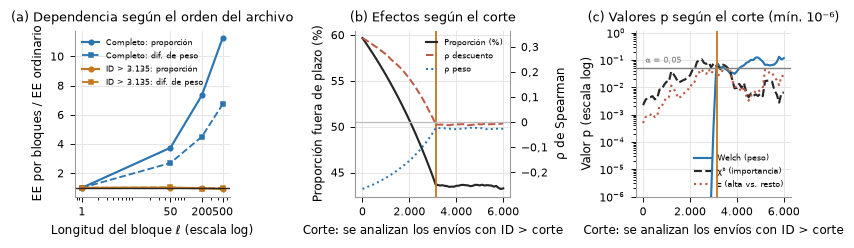

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.3))
ax = axes[0]
for conj in CONJUNTOS:
    t = tab_bloques[tab_bloques["conjunto"] == conj]
    ax.plot(t["longitud_bloque"], t["razon_ee_proporcion"], "o-", color=COLOR_CONJ[conj], lw=1.4, ms=3.0, label=f"{conj}: proporción")
    ax.plot(t["longitud_bloque"], t["razon_ee_dif_peso"], "s--", color=COLOR_CONJ[conj], lw=1.2, ms=3.0, label=f"{conj}: dif. de peso")
ax.axhline(1, color="#262626", lw=0.9)
ax.set_xscale("log")
ax.set_xticks([1, 50, 200, 500]); ax.set_xticklabels(["1", "50", "200", "500"])
ax.set_xlabel("Longitud del bloque ℓ (escala log)"); ax.set_ylabel("EE por bloques / EE ordinario")
ax.set_title("(a) Dependencia según el orden del archivo")
ax.legend(fontsize=5.5, loc="upper left")
ax = axes[1]
ax.plot(tab_corte["corte"], 100 * tab_corte["proporcion"], color="#262626", lw=1.4, label="Proporción (%)")
ax2 = ax.twinx()
ax2.plot(tab_corte["corte"], tab_corte["rho_descuento"], color=C_BCA, lw=1.3, ls="--", label="ρ descuento")
ax2.plot(tab_corte["corte"], tab_corte["rho_peso"], color=C_COMPLETO, lw=1.3, ls=":", label="ρ peso")
ax2.axhline(0, color="#BBBBBB", lw=0.8)
ax2.set_ylabel("ρ de Spearman"); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.axvline(CORTE_ID, color=C_SUB, lw=1.2)
ax.set_xlabel("Corte: se analizan los envíos con ID > corte"); ax.set_ylabel("Proporción fuera de plazo (%)")
ax.set_title("(b) Efectos según el corte")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, ["Proporción (%)", "ρ descuento", "ρ peso"], fontsize=5.5, loc="upper right", handlelength=1.4)
ax = axes[2]
for col, etiqueta, colr, ls in [("p_welch", "Welch (peso)", C_COMPLETO, "-"), ("p_chi2", "χ² (importancia)", "#262626", "--"), ("p_z", "z (alta vs. resto)", C_BCA, ":")]:
    ax.plot(tab_corte["corte"], tab_corte[col], color=colr, ls=ls, lw=1.4, label=etiqueta)
ax.set_yscale("log"); ax.set_ylim(1e-6, 1.2)
ax.axhline(ALFA, color="#7F7F7F", lw=0.9)
ax.text(100, ALFA * 1.6, "α = 0,05", ha="left", fontsize=5.5, color="#7F7F7F")
ax.axvline(CORTE_ID, color=C_SUB, lw=1.2)
ax.set_xlabel("Corte: se analizan los envíos con ID > corte"); ax.set_ylabel("Valor p (escala log)")
ax.set_title("(c) Valores p según el corte (mín. 10⁻⁶)")
ax.legend(fontsize=5.5, loc="lower right")
fig.tight_layout()
guardar_figura(fig, "s2_fig06_robustez")
plt.show()

### 5.4 Interpretación

**Valores atípicos.** El costo y el peso son estables: sus medias cambian como máximo 0,7 % en el conjunto completo y 1,7 % en el subconjunto al recortar extremos. El descuento medio del conjunto completo cae 14,1 % con un recorte del 5 %; tiene 2.209 atípicos según la regla del rango intercuartílico, concentrados en el bloque inicial. En el subconjunto no hay atípicos del descuento y el recorte apenas lo mueve (0,04 %); el peso sí tiene 1.906 atípicos según esa regla, pero corresponden al modo inferior de una distribución bimodal y no a errores. La diferencia de peso entre grupos es −896 g con medias, −992 g con medias recortadas y −1.443 g con medianas en el conjunto completo, frente a −67, −74 y −38 g en el subconjunto. La conclusión de S1 se sostiene con estimadores robustos en el completo y desaparece con cualquiera de ellos en el subconjunto. Según el jackknife, ninguna observación individual mueve una media más de 0,03 errores estándar: la influencia es **de grupo** (el bloque), no de casos aislados.

**Independencia.** Es el hallazgo nuevo más importante de esta sección. En el conjunto completo, el error estándar de la proporción crece 3,7 veces con bloques de 50 envíos, 7,3 veces con 200 y 11,3 veces con 500; el de la diferencia de peso, 6,7 veces con 500. En el subconjunto las razones quedan entre 0,92 y 1,03. El conjunto completo no se comporta como una colección de envíos intercambiables: los envíos cercanos en el ID comparten régimen. La razón no se estabiliza al crecer ℓ, señal de un quiebre en la serie (no estacionariedad) más que de dependencia estacionaria: se interpreta como diagnóstico de estructura por orden, no como un error estándar corregido. Los IC de S1 para el conjunto completo son precisos solo bajo independencia; en el subconjunto ese supuesto es plausible, y también lo es la independencia que supone el Monte Carlo. Con bloques de 500 envíos, los IC de las correlaciones del conjunto completo se ensanchan entre 2,5 y 9 veces, pero incluso con estos IC, más conservadores, todos siguen excluyendo el 0: el cambio de signo de costo y llamadas entre conjuntos no es un artefacto de suponer independencia. En el subconjunto los IC prácticamente no cambian. Esto respalda usar ID > 3.135 como análisis principal en S3 y validar con particiones por bloques de ID.

**Corte post hoc.** En los 30 cortes iguales o mayores a 3.135, la proporción fuera de plazo se mantiene entre 43,2 % y 43,7 %, la diferencia de peso entre −84 y −65 g, ρ del descuento entre −0,012 y −0,005, y ρ del peso entre −0,028 y −0,022. Bajo 3.135 todas las medidas derivan de forma continua a medida que entran envíos del bloque. Las estimaciones del subconjunto no dependen del corte exacto: el corte coincide con el punto donde los efectos se estabilizan. En los valores p, Welch es significativo solo en 23 % de esos cortes, mientras que χ² lo es en 83 % y z en 97 %. La señal de la importancia persiste en la mayoría de los cortes, pero oscila alrededor de 0,05 justo en el corte de S1: es una señal frágil, no ausente.

## 6. Reporte de resultados validados para la Sumativa 3

Esta sección consolida qué resultados de S1 llegan validados a la Sumativa 3, con qué evidencia y con qué cautela. El reporte se genera **desde los resultados de este notebook** (no se transcribe a mano) y se exporta como archivo separado:

- `S2/resultados_validados.csv`: una fila por resultado, con valor de S1, validación, evidencia de S2, las dos dimensiones de la evaluación, el estado y la implicancia para S3.
- `S2/resultados_validados.md`: la misma tabla en formato legible, más observaciones influyentes y recomendaciones metodológicas.

**Regla de clasificación (única para todos los resultados).** Cada resultado se evalúa en dos dimensiones:

- *Coherente entre métodos:* los métodos de S2 confirman el resultado de S1 (IC percentil con amplitud entre 0,9 y 1,1 veces la del IC clásico y BCa desplazado menos de 0,25 errores estándar, o, si el IC clásico tiene amplitud cero, percentil igual al IC exacto; permutación con la misma decisión que la prueba clásica).
- *Estable entre conjuntos:* el resultado se mantiene en ID > 3.135 (parámetros: cambio menor a 5 %; pruebas: misma decisión, usando en el subconjunto el valor p ajustado por Holm; correlaciones: estado «Estable» de la sección 3).

| Estado | Criterio |
|---|---|
| Robusto | Coherente entre métodos y estable entre conjuntos |
| Señal exploratoria | Coherente entre métodos y no estable, pero con la misma dirección del efecto en ambos conjuntos (para χ², más retrasos en importancia alta) y significativo en la mayoría de los cortes ≥ 3.135 de la sección 5.3 |
| Dependiente del bloque | Coherente entre métodos, pero cambia, se atenúa, desaparece o invierte su signo en ID > 3.135 |

In [30]:
def fila_b(conj, par):
    return tab_boot.query("conjunto == @conj and parametro == @par").iloc[0]


def fila_p(conj, prueba):
    return tab_perm.query("conjunto == @conj and prueba == @prueba").iloc[0]


def fila_c(conj, var):
    return tab_corr.query("conjunto == @conj and variable == @var").iloc[0]


def fila_r(conj, var):
    return tab_rob.query("conjunto == @conj and variable == @var").iloc[0]


def fila_cb(conj, var):
    return tab_corr_bloq.query("conjunto == @conj and variable == @var").iloc[0]


razon_p = tab_bloques.query("conjunto == 'Completo' and longitud_bloque == 500")["razon_ee_proporcion"].iloc[0]
razon_p_sub = tab_bloques.query("conjunto == 'ID > 3.135' and longitud_bloque == 500")["razon_ee_proporcion"].iloc[0]
pct_cortes = {k: resumen_corte.query("medida == @m")["minimo_cortes_ge_3135"].iloc[0]
              for k, m in [("t_welch", "Cortes con p_welch < 0,05 (%)"), ("chi2", "Cortes con p_chi2 < 0,05 (%)"), ("z_alta", "Cortes con p_z < 0,05 (%)")]}
pot_sub = tab_pot.query("conjunto == 'ID > 3.135' and diferencia_pp == 4").iloc[0]
pp = lambda v: f"{es(100 * v, 2)} %"
ic = lambda lo, hi, d=2, f=1: f"[{es(f * lo, d)}; {es(f * hi, d)}]"


def coherente_ic(b):
    if np.isnan(b.amplitud_percentil_vs_clasico):   # IC clásico de amplitud cero (mediana degenerada)
        return bool(np.isclose(b.percentil_inf, b.clasico_inf) and np.isclose(b.percentil_sup, b.clasico_sup))
    return bool(0.9 <= b.amplitud_percentil_vs_clasico <= 1.1 and (np.isnan(b.desplazamiento_bca_rel_se) or abs(b.desplazamiento_bca_rel_se) < 0.25))


def estado(coherente, estable, exploratoria=False):
    if coherente and estable:
        return "Robusto"
    if coherente and exploratoria:
        return "Señal exploratoria"
    return "Dependiente del bloque" if coherente else "Revisar"


R = []
IMPL = {
    "Proporción fuera de plazo": "El IC de S1 es exacto bajo independencia, pero la tasa depende del régimen (59,7 % frente a 43,6 %): reportar ambos.",
    "Costo medio": "Usable como descriptor en ambos conjuntos.",
    "Peso medio": "Distribución bimodal y dependiente del bloque: preferir la mediana y no imputar con supuesto normal.",
    "Descuento medio": "Dominada por el bloque inicial: no usar como resumen del régimen habitual.",
    "Mediana del peso": "Resumen preferente del peso, pero informar por régimen.",
    "Mediana del descuento": "IC no informativo por ser discreta la variable: informar la distribución bootstrap.",
}
for par in ["Proporción fuera de plazo", "Costo medio", "Peso medio", "Mediana del peso", "Descuento medio", "Mediana del descuento"]:
    b, bs = fila_b("Completo", par), fila_b("ID > 3.135", par)
    cambio = 100 * (bs.estimacion - b.estimacion) / b.estimacion
    coh, est = coherente_ic(b) and coherente_ic(bs), abs(cambio) < 5
    f, d = (100, 2) if par.startswith("Proporción") else (1, 0 if "Mediana" in par else 2)
    if par.startswith("Mediana del descuento"):
        detalle = (f"Distribución bootstrap degenerada (100 % de réplicas = {es(b.estimacion, 0)}); percentil = orden exacto "
                   f"{ic(b.clasico_inf, b.clasico_sup, 0)}; suavizado {ic(tab_suav.loc[0, 'suavizado_inf'], tab_suav.loc[0, 'suavizado_sup'])}.")
    elif par.startswith("Mediana"):
        detalle = f"Percentil = orden exacto {ic(b.clasico_inf, b.clasico_sup, 0)}; BC {ic(b.bca_inf, b.bca_sup, 0)}."
    else:
        detalle = (f"Percentil {ic(b.percentil_inf, b.percentil_sup, d, f)} y BCa {ic(b.bca_inf, b.bca_sup, d, f)} coinciden con el clásico "
                   f"(z0 = {es(b.z0, 3)}, a = {es(b.a, 4)}).")
    extra = f" Con bloques de 500 envíos, el EE se multiplica por {es(razon_p, 1)} (por {es(razon_p_sub, 2)} en ID > 3.135)." if par.startswith("Proporción") else ""
    R.append((par + (" (nuevo en S2)" if par.startswith("Mediana") else ""),
              f"{es(f * b.estimacion, d)}{' %' if f == 100 else ''} {ic(b.clasico_inf, b.clasico_sup, d, f)}",
              "Bootstrap percentil, BCa/BC e IC por estadísticos de orden" if par.startswith("Mediana") else "Bootstrap percentil y BCa",
              f"{detalle}{extra} En ID > 3.135: {es(f * bs.estimacion, d)} ({es(cambio, 1)} %).",
              "Sí" if coh else "No", "Sí" if est else "No", estado(coh, est), IMPL[par]))

for clave, prueba, nombre, impl in [
        ("t_welch", "Peso: t de Welch", "Prueba 1: peso según cumplimiento (Welch)", "El peso no discrimina el cumplimiento en el régimen habitual."),
        ("dif_mediana", "Peso: diferencia de medianas", "Diferencia de medianas del peso (nuevo en S2)", "Confirma con un estimador robusto que el efecto del peso depende del bloque."),
        ("chi2", "Importancia: χ²", "Prueba 2: importancia × cumplimiento (χ²)", "Asociación muy débil (V ≈ 0,03); no tratarla como confirmada."),
        ("z_alta", "Alta vs. resto: z", "Contraste importancia alta vs. resto (z)", "Candidata a predictor en S3, sin interpretarla como confirmada; validar fuera de muestra.")]:
    p, ps = fila_p("Completo", prueba), fila_p("ID > 3.135", prueba)
    coh = p.concordancia == "Concuerda" and ps.concordancia == "Concuerda"
    est = (p.p_perm_final < ALFA) == (ps.p_holm_subconjunto < ALFA)     # en el subconjunto, decisión tras Holm
    mayoria = pct_cortes.get(clave, 0) > 50
    misma_dir = np.sign(p.estadistico_obs) == np.sign(ps.estadistico_obs)
    v_s1 = (f"p = {es(p.p_clasico, 4)}" if p.p_clasico >= 1e-4 else "p < 0,0001") + f"; {p.efecto}"
    texto_cortes = f" p < 0,05 en {es(pct_cortes[clave], 0)} % de los cortes ≥ 3.135." if clave in pct_cortes else ""
    R.append((nombre, v_s1, "Permutación (10.000; 100.000 en ID > 3.135); Holm; barrido del corte",
              f"Permutación concuerda en ambos conjuntos. ID > 3.135: p = {es(ps.p_perm_final, 4)}, Holm {es(ps.p_holm_subconjunto, 3)} ({ps.efecto}).{texto_cortes}",
              "Sí" if coh else "No", "Sí" if est else "No", estado(coh, est, exploratoria=bool(misma_dir and mayoria)), impl))

IMPL_C = {"Descuento": "Separación casi perfecta en el completo y nula en el subconjunto: decidir su tratamiento antes de modelar.",
          "Peso": "Mantiene el signo, con magnitud mínima sin el bloque.",
          "Compras previas": "Sin asociación en el régimen habitual.",
          "Costo": "Efecto de composición: interpretar solo dentro de un régimen.",
          "Llamadas": "Efecto de composición (S1, Tabla 17): interpretar solo dentro de un régimen."}
for var in ("Descuento", "Peso", "Compras previas", "Costo", "Llamadas"):
    c, cs, cb = fila_c("Completo", var), fila_c("ID > 3.135", var), fila_cb("Completo", var)
    est = c.estado == "Estable"
    bloq_txt = f" Con bloques de 500 envíos, IC del completo {ic(cb.ic_bloques_inf, cb.ic_bloques_sup, 3)}" + ("." if cb.excluye_cero_bloques else ", que incluye el 0.")
    R.append((f"ρ Spearman {var.lower()}–retraso", f"{es(c.rho, 3)} {ic(c.ic_inf, c.ic_sup, 3)}", "IC bootstrap percentil (10.000), ordinario y por bloques",
              f"ID > 3.135: {es(cs.rho, 3)} {ic(cs.ic_inf, cs.ic_sup, 3)}; clasificación: {c.estado.lower()}.{bloq_txt}",
              "Sí", "Sí" if est else "No", estado(True, est), IMPL_C[var]))

cf = tab_esc.query("escenario.str.startswith('Intervención')", engine="python").iloc[0]
R.append(("Lote de 1.000 envíos (Monte Carlo con parámetros de S1)", f"Tasa {pp(t10.loc[0, 'estimacion'])}",
          "Monte Carlo en dos niveles (10.000 lotes por escenario)",
          f"Intervalo central 95 % del lote {ic(base['p2_5'], base['p97_5'], 1, 100)} frente al IC de S1 {ic(t10.loc[0, 'ic_inferior'], t10.loc[0, 'ic_superior'], 1, 100)}; "
          f"P(lote > 60,59 %) = {es(base['prob_sobre_umbral'], 3)}. Con los parámetros de ID > 3.135, la tasa esperada es {pp(fila_sub['media_tasa'])}. "
          f"Retrasos evitables por cada 1.000 envíos si la importancia alta tuviera la tasa del resto: {es(cf['evitados_medio'], 1)} {ic(cf['evitados_p2_5'], cf['evitados_p97_5'], 0)}.",
          "Sí", "No", "Dependiente del bloque",
          "Comunicar intervalos de predicción por lote, no solo el IC del parámetro; el régimen domina la incertidumbre."))
cols = ["resultado_s1", "valor_s1", "validacion_s2", "evidencia_s2", "coherente_metodos", "estable_conjuntos", "estado", "implicancia_s3"]
tab_val = pd.DataFrame(R, columns=cols)
assert (tab_val["estado"] != "Revisar").all()
tab_val.to_csv(RAIZ / "S2" / "resultados_validados.csv", index=False, encoding="utf-8")
guardar_tabla(tab_val, "s2_tab06_resultados_validados")
print(tab_val["estado"].value_counts().to_string())
tab_val[["resultado_s1", "coherente_metodos", "estable_conjuntos", "estado"]]

estado
Dependiente del bloque    13
Señal exploratoria         2
Robusto                    1


,resultado_s1,coherente_metodos,estable_conjuntos,estado
0,Proporción fuera de plazo,Sí,No,Dependiente del bloque
1,Costo medio,Sí,Sí,Robusto
2,Peso medio,Sí,No,Dependiente del bloque
3,Mediana del peso (nuevo en S2),Sí,No,Dependiente del bloque
4,Descuento medio,Sí,No,Dependiente del bloque
5,Mediana del descuento (nuevo en S2),Sí,No,Dependiente del bloque
6,Prueba 1: peso según cumplimiento (Welch),Sí,No,Dependiente del bloque
7,Diferencia de medianas del peso (nuevo en S2),Sí,No,Dependiente del bloque
8,Prueba 2: importancia × cumplimiento (χ²),Sí,No,Señal exploratoria
9,Contraste importancia alta vs. resto (z),Sí,No,Señal exploratoria


### 6.1 Observaciones influyentes y recomendaciones metodológicas para S3

Las recomendaciones se escriben en el archivo `S2/resultados_validados.md` junto con la tabla. Se construyen a partir de las cifras calculadas en las secciones 1 a 5.

In [31]:
r_desc = fila_r("Completo", "Descuento")
n_desc10 = int((df["Discount_offered"] > 10).sum())
media_desc_sin10 = df.loc[df["Discount_offered"] <= 10, "Discount_offered"].mean()
n_bloque = int((df["ID"] <= CORTE_ID).sum())
fid_normal = tab_fid.query("generador == 'Paramétrico normal'").iloc[0]
fid_pert = tab_fid.query("generador == 'Perturbación'").iloc[0]
banda_real = tab_fid.query("generador == 'Real'")["fraccion_2000_3999"].iloc[0]
holm_z = fila_p("ID > 3.135", "Alta vs. resto: z")["p_holm_subconjunto"]

influyentes = [
    f"**Bloque inicial (ID ≤ 3.135):** {es(n_bloque, 0)} envíos ({es(100 * n_bloque / len(df), 1)} % del archivo), todos fuera de plazo. "
    f"Es la subpoblación influyente principal: concentra la asociación del descuento, del peso y de la importancia, y la estructura por orden detectada con el bootstrap por bloques "
    f"(EE de la proporción × {es(razon_p, 1)} con bloques de 500).",
    f"**Descuentos mayores a 10:** {es(n_desc10, 0)} envíos, todos fuera de plazo y todos dentro del bloque inicial. "
    f"Sin ellos la media del descuento cae de {es(r_desc.media, 2)} a {es(media_desc_sin10, 2)}; el recorte al 5 % la lleva a {es(r_desc.media_recortada_5, 2)} ({es(r_desc.cambio_recortada_pct, 1)} %).",
    f"**Observación individual más influyente en la media del descuento:** valor {es(r_desc.valor_mas_influyente, 0)}, que mueve la media en "
    f"{es(r_desc.influencia_max_en_ee, 2)} errores estándar jackknife. Ningún envío individual cambia por sí solo una conclusión: la influencia es de grupo, no de casos aislados.",
    f"**Peso en el subconjunto:** {es(fila_r('ID > 3.135', 'Peso').atipicos_iqr, 0)} valores atípicos según la regla del rango intercuartílico, que corresponden al modo inferior de una distribución bimodal y no a errores: no deben eliminarse.",
]
recomendaciones = [
    "**Tratamiento del bloque inicial.** Ajustar los modelos de S3 en ID > 3.135 como análisis principal y repetir en el conjunto completo con un indicador del bloque como análisis de sensibilidad. La partición entrenamiento/prueba y la validación cruzada deben respetar el orden por ID (bloques contiguos), porque el bootstrap por bloques mostró estructura según el orden en el conjunto completo.",
    f"**Descuento y separación casi perfecta.** En el conjunto completo, descuento > 10 implica retraso en el 100 % de los casos ({es(n_desc10, 0)} envíos): incluirlo en una regresión logística producirá coeficientes y odds ratios explosivos. En ID > 3.135 su correlación es nula ({es(fila_c('ID > 3.135', 'Descuento').rho, 3)}). Recomendación: excluirlo del modelo principal o, si se incluye, usar regresión penalizada de Firth (1993) y reportarlo aparte.",
    "**Fuga de información.** Antes de modelar, confirmar qué variables existen antes de la entrega. El descuento, las llamadas al servicio y la calificación del cliente podrían registrarse después del despacho o como consecuencia del retraso; si es así, deben excluirse del modelo predictivo.",
    f"**Selección de predictores.** La importancia alta es la única señal con la misma dirección en ambos conjuntos, pero es exploratoria (Holm p = {es(holm_z, 3)}). Con n = 7.864, la potencia para detectar una diferencia de 4 pp es de {es(100 * pot_sub.potencia, 0)} %, y se necesitarían unos {es(round(N80['ID > 3.135'], -3), 0)} envíos para una potencia de 80 % ante la diferencia estimada en S1. El peso mantiene su dirección con magnitud mínima. Costo y llamadas cambian de signo entre conjuntos: si se incluyen, interpretarlos dentro de un régimen o con interacción con el bloque.",
    f"**Imputación (S3).** El archivo no tiene faltantes, por lo que habrá que inducirlos de forma controlada. Para el peso no conviene un supuesto normal: un generador normal con los parámetros de S1 reproduce la media, pero no la bimodalidad (KS D = {es(fid_normal.ks_D, 3)}; fracción 2.000–3.999 g de {es(fid_normal.fraccion_2000_3999, 3)} frente a {es(banda_real, 3)} real), mientras que la perturbación de valores reales sí la conserva (KS D = {es(fid_pert.ks_D, 3)}). Preferir imputación con residuos empíricos o por emparejamiento predictivo (PMM; van Buuren y Groothuis-Oudshoorn, 2011).",
    f"**Línea base y métricas.** Comparar todo modelo contra la clase mayoritaria: {es(100 * t10.loc[0, 'estimacion'], 1)} % de accuracy en el completo y {es(100 * (1 - sub[Y].mean()), 1)} % (prediciendo «a tiempo») en ID > 3.135. Reportar AUC, recall y precisión además de la accuracy.",
    "**Bootstrap de coeficientes.** Con n cercano a 10.000, z0 y a fueron cercanos a cero en todas las medias, y el estudio de cobertura muestra que los tres métodos alcanzan el 95 % con muestras grandes. Esto no se traslada automáticamente a los coeficientes de una regresión logística con casi-separación: allí conviene usar BCa con B ≥ 10.000, revisar la estabilidad de los odds ratios y, en el conjunto completo, remuestrear por bloques.",
    "**Multiplicidad.** Mantener la distinción entre contrastes confirmatorios y exploratorios, y aplicar Holm cuando se evalúen varios predictores en el subconjunto.",
]

tabla_md = ["| Resultado de S1 | Valor en S1 | Validación en S2 | Evidencia | Coherente entre métodos | Estable entre conjuntos | Estado | Implicancia para S3 |",
            "|---|---|---|---|---|---|---|---|"]
for _, f in tab_val.iterrows():
    tabla_md.append("| " + " | ".join(str(f[c]).replace("|", "/") for c in cols) + " |")
contenido = "\n".join([
    "# Resultados validados para la Sumativa 3",
    "",
    "Grupo 6 · Marco Álvarez Araya y Ricardo Jaramillo · MCDI501 · 20-10-2026",
    "",
    "Generado por `S2/notebooks/s2-ecommerce-validacion.ipynb` (sección 6). La versión tabular está en `S2/resultados_validados.csv`.",
    "",
    "## Regla de clasificación",
    "",
    "- **Coherente entre métodos:** IC percentil con amplitud entre 0,9 y 1,1 veces la del IC clásico y BCa desplazado menos de 0,25 EE (si el IC clásico tiene amplitud cero, percentil igual al IC exacto); permutación con la misma decisión que la prueba clásica.",
    "- **Estable entre conjuntos:** el resultado se mantiene en ID > 3.135 (parámetros: cambio menor a 5 %; pruebas: misma decisión, con Holm en el subconjunto; correlaciones: estado «Estable»).",
    "- **Robusto:** coherente entre métodos y estable entre conjuntos.",
    "- **Señal exploratoria:** coherente entre métodos y no estable, pero con la misma dirección del efecto en ambos conjuntos (para χ², más retrasos en importancia alta) y significativo en la mayoría de los cortes ≥ 3.135.",
    "- **Dependiente del bloque:** coherente entre métodos, pero cambia, se atenúa, desaparece o invierte su signo en ID > 3.135.",
    "",
    "## Resultados",
    "",
    *tabla_md,
    "",
    "## Observaciones influyentes",
    "",
    *[f"- {t}" for t in influyentes],
    "",
    "## Recomendaciones metodológicas para la Sumativa 3",
    "",
    *[f"{i}. {t}" for i, t in enumerate(recomendaciones, start=1)],
    "",
    "## Referencias citadas en este archivo",
    "",
    "- Firth, D. (1993). Bias reduction of maximum likelihood estimates. *Biometrika, 80*(1), 27–38. https://doi.org/10.1093/biomet/80.1.27",
    "- van Buuren, S., y Groothuis-Oudshoorn, K. (2011). mice: Multivariate imputation by chained equations in R. *Journal of Statistical Software, 45*(3), 1–67. https://doi.org/10.18637/jss.v045.i03",
    "",
])
(RAIZ / "S2" / "resultados_validados.md").write_text(contenido, encoding="utf-8")
display(Markdown("\n".join(["**Observaciones influyentes**", "", *[f"- {t}" for t in influyentes], "",
                            "**Recomendaciones para S3**", "", *[f"{i}. {t}" for i, t in enumerate(recomendaciones, start=1)]])))

**Observaciones influyentes**

- **Bloque inicial (ID ≤ 3.135):** 3.135 envíos (28,5 % del archivo), todos fuera de plazo. Es la subpoblación influyente principal: concentra la asociación del descuento, del peso y de la importancia, y la estructura por orden detectada con el bootstrap por bloques (EE de la proporción × 11,3 con bloques de 500).
- **Descuentos mayores a 10:** 2.647 envíos, todos fuera de plazo y todos dentro del bloque inicial. Sin ellos la media del descuento cae de 13,37 a 5,51; el recorte al 5 % la lleva a 11,49 (−14,1 %).
- **Observación individual más influyente en la media del descuento:** valor 65, que mueve la media en 0,03 errores estándar jackknife. Ningún envío individual cambia por sí solo una conclusión: la influencia es de grupo, no de casos aislados.
- **Peso en el subconjunto:** 1.906 valores atípicos según la regla del rango intercuartílico, que corresponden al modo inferior de una distribución bimodal y no a errores: no deben eliminarse.

**Recomendaciones para S3**

1. **Tratamiento del bloque inicial.** Ajustar los modelos de S3 en ID > 3.135 como análisis principal y repetir en el conjunto completo con un indicador del bloque como análisis de sensibilidad. La partición entrenamiento/prueba y la validación cruzada deben respetar el orden por ID (bloques contiguos), porque el bootstrap por bloques mostró estructura según el orden en el conjunto completo.
2. **Descuento y separación casi perfecta.** En el conjunto completo, descuento > 10 implica retraso en el 100 % de los casos (2.647 envíos): incluirlo en una regresión logística producirá coeficientes y odds ratios explosivos. En ID > 3.135 su correlación es nula (−0,010). Recomendación: excluirlo del modelo principal o, si se incluye, usar regresión penalizada de Firth (1993) y reportarlo aparte.
3. **Fuga de información.** Antes de modelar, confirmar qué variables existen antes de la entrega. El descuento, las llamadas al servicio y la calificación del cliente podrían registrarse después del despacho o como consecuencia del retraso; si es así, deben excluirse del modelo predictivo.
4. **Selección de predictores.** La importancia alta es la única señal con la misma dirección en ambos conjuntos, pero es exploratoria (Holm p = 0,143). Con n = 7.864, la potencia para detectar una diferencia de 4 pp es de 49 %, y se necesitarían unos 14.000 envíos para una potencia de 80 % ante la diferencia estimada en S1. El peso mantiene su dirección con magnitud mínima. Costo y llamadas cambian de signo entre conjuntos: si se incluyen, interpretarlos dentro de un régimen o con interacción con el bloque.
5. **Imputación (S3).** El archivo no tiene faltantes, por lo que habrá que inducirlos de forma controlada. Para el peso no conviene un supuesto normal: un generador normal con los parámetros de S1 reproduce la media, pero no la bimodalidad (KS D = 0,135; fracción 2.000–3.999 g de 0,430 frente a 0,163 real), mientras que la perturbación de valores reales sí la conserva (KS D = 0,019). Preferir imputación con residuos empíricos o por emparejamiento predictivo (PMM; van Buuren y Groothuis-Oudshoorn, 2011).
6. **Línea base y métricas.** Comparar todo modelo contra la clase mayoritaria: 59,7 % de accuracy en el completo y 56,4 % (prediciendo «a tiempo») en ID > 3.135. Reportar AUC, recall y precisión además de la accuracy.
7. **Bootstrap de coeficientes.** Con n cercano a 10.000, z0 y a fueron cercanos a cero en todas las medias, y el estudio de cobertura muestra que los tres métodos alcanzan el 95 % con muestras grandes. Esto no se traslada automáticamente a los coeficientes de una regresión logística con casi-separación: allí conviene usar BCa con B ≥ 10.000, revisar la estabilidad de los odds ratios y, en el conjunto completo, remuestrear por bloques.
8. **Multiplicidad.** Mantener la distinción entre contrastes confirmatorios y exploratorios, y aplicar Holm cuando se evalúen varios predictores en el subconjunto.

## 7. Cierre y reproducibilidad

- Todas las secciones aleatorias reinician `numpy.random.default_rng(42)`; el notebook produce exactamente las mismas tablas en cada ejecución completa (*Restart & Run All*).
- Los parámetros de S1 se leen desde `S1/resultados/tablas/` y se verifican contra el recálculo (sección 0.3).
- Se exportan las tablas `s2_tab*.csv` y las figuras `s2_fig*.png` en `S2/resultados/`, y el reporte para S3 en `S2/resultados_validados.csv` y `.md`.

### Referencias

- Chung, E., y Romano, J. P. (2013). Exact and asymptotically robust permutation tests. *The Annals of Statistics, 41*(2), 484–507.
- Efron, B. (1987). Better bootstrap confidence intervals. *Journal of the American Statistical Association, 82*(397), 171–185.
- Efron, B., y Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.
- Firth, D. (1993). Bias reduction of maximum likelihood estimates. *Biometrika, 80*(1), 27–38.
- Geweke, J. (1992). Evaluating the accuracy of sampling-based approaches to the calculation of posterior moments. En J. M. Bernardo et al. (Eds.), *Bayesian Statistics 4* (pp. 169–193). Oxford University Press.
- Good, P. I. (2005). *Permutation, parametric, and bootstrap tests of hypotheses* (3.ª ed.). Springer.
- Hall, P., DiCiccio, T. J., y Romano, J. P. (1989). On smoothing and the bootstrap. *The Annals of Statistics, 17*(2), 692–704.
- Hoenig, J. M., y Heisey, D. M. (2001). The abuse of power: The pervasive fallacy of power calculations for data analysis. *The American Statistician, 55*(1), 19–24.
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics, 6*(2), 65–70.
- Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *The Annals of Statistics, 17*(3), 1217–1241.
- Politis, D. N., y Romano, J. P. (1992). A circular block-resampling procedure for stationary data. En R. LePage y L. Billard (Eds.), *Exploring the limits of bootstrap* (pp. 263–270). Wiley.
- Robert, C. P., y Casella, G. (2004). *Monte Carlo statistical methods* (2.ª ed.). Springer.
- van Buuren, S., y Groothuis-Oudshoorn, K. (2011). mice: Multivariate imputation by chained equations in R. *Journal of Statistical Software, 45*(3), 1–67.
- Virtanen, P., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*, 261–272.

In [32]:
# Inventario de salidas generadas por este notebook.
salidas = sorted(p.relative_to(RAIZ).as_posix() for p in (RAIZ / "S2").rglob("*") if p.suffix in {".csv", ".png", ".md"})
print(f"{len(salidas)} archivos generados:")
print("\n".join(salidas))

30 archivos generados:
S2/resultados/figuras/s2_fig01_bootstrap_ic.png
S2/resultados/figuras/s2_fig02_permutacion.png
S2/resultados/figuras/s2_fig03_correlaciones.png
S2/resultados/figuras/s2_fig04_montecarlo.png
S2/resultados/figuras/s2_fig05_escenarios_sensibilidad.png
S2/resultados/figuras/s2_fig06_robustez.png
S2/resultados/tablas/s2_tab00_control_insumos_s1.csv
S2/resultados/tablas/s2_tab01_bootstrap_ic.csv
S2/resultados/tablas/s2_tab01b_mediana_descuento_suavizado.csv
S2/resultados/tablas/s2_tab02_permutacion.csv
S2/resultados/tablas/s2_tab03_correlaciones_bootstrap.csv
S2/resultados/tablas/s2_tab04a_parametros_montecarlo.csv
S2/resultados/tablas/s2_tab04b_convergencia.csv
S2/resultados/tablas/s2_tab04c_semillas.csv
S2/resultados/tablas/s2_tab04d_escenarios.csv
S2/resultados/tablas/s2_tab04e_verificacion_generador.csv
S2/resultados/tablas/s2_tab04f_fidelidad_peso.csv
S2/resultados/tablas/s2_tab04g_potencia_sintetica.csv
S2/resultados/tablas/s2_tab04h_tornado.csv
S2/resultados/tab